
### (Data Collection → Data Preprocessing → Data Transformation)

---

Notebook ghi lại **toàn bộ quy trình đã thực hiện cho đến bước Biến đổi dữ liệu (Transformation)** của dự án khai phá dữ liệu chuyến bay Việt Nam (đúng giờ / trễ / hủy). Mọi con số trong notebook được **tính trực tiếp từ dữ liệu và mã nguồn của dự án** (`config.py`, `collector.py`, `weather.py`, `processor.py`), không nhập tay.

## Phạm vi theo 6 bước của quy trình khai phá dữ liệu

| Bước | Nội dung | Trong notebook này |
| :--- | :--- | :--- |
| 1. Thu thập dữ liệu | Website sân bay (Playwright), REST API (Aviationstack), API thời tiết (Open-Meteo) | **Phần 2** |
| 2. Tiền xử lý | Làm sạch lỗi, khử trùng lặp, xử lý giá trị thiếu và ngoại lai | **Phần 3** |
| 3. Biến đổi dữ liệu | Chọn biến, gán nhãn, tạo đặc trưng, ghép thời tiết, rời rạc hóa | **Phần 4** |
| 4. Khai phá dữ liệu | FP-Growth, mô hình dự báo | Chưa thực hiện (bước tiếp theo) |
| 5. Đánh giá và diễn giải | Độ tin cậy, ý nghĩa của kết quả | Chưa thực hiện |
| 6. Ứng dụng | Dùng kết quả hỗ trợ quyết định | Chưa thực hiện |

## Cách chạy
1. Đặt notebook trong **thư mục gốc dự án** (cùng cấp với `main.py`, `config.py`).
2. Ngoài `requirements.txt`, cần: `pip install matplotlib jupyter ipykernel`.
3. Chọn **Restart & Run All**. Nên chạy sau khi đã có dữ liệu: `python main.py collect`, `python main.py api`, `python main.py weather`.

> **Lưu ý về tác dụng phụ:** ô ở mục 2.6 gọi `rebuild_raw_csv()` và ô ở mục 3.3 gọi `prepare_dataset()` (hàm này cũng gọi `rebuild_raw_csv()`). Hàm này **dựng lại `data/raw/*.csv` từ JSON gốc**; lần đầu tiên, các CSV cũ được sao lưu sang `data/raw_legacy/`. Notebook **không ghi đè** `flights_cleaned_global.csv` trừ khi bạn đặt `SAVE_OUTPUT = True` ở mục 4.6.

## 1. Mục đích, Nguồn dữ liệu (5W1H) và Kiến trúc Thu thập

### 1.1. Bài toán
> **Những điều kiện về thời tiết, thời gian và sân bay nào đi kèm với chuyến bay bị trễ hoặc hủy tại 5 sân bay lớn của Việt Nam?**

- **Đơn vị phân tích:** một dòng = một chuyến bay (*flight leg*: chuyến + ngày + sân bay đi → sân bay đến).
- **Nhãn đích `status_clean`:** `on_time` / `delayed` / `cancelled`.
- **Hãng được giữ lại:** Vietnam Airlines `VN`, Vietjet `VJ`, Bamboo `QH`, Pacific Airlines `BL`, Vietravel `VU`, Sun PhuQuoc `9G`, VASCO `0V`.
- **Sân bay được theo dõi đầy đủ:** Tân Sơn Nhất `SGN`, Nội Bài `HAN`, Đà Nẵng `DAD`, Cam Ranh `CXR`, Phú Quốc `PQC`.

### 1.2. Phân tích 5W1H của 3 nhóm nguồn dữ liệu

| Tiêu chí | Nhóm 1: Bảng FIDS sân bay (Airport Guide) | Nhóm 2: Aviationstack REST API | Nhóm 3: Open-Meteo |
| :--- | :--- | :--- | :--- |
| **WHAT** | Bảng HTML chuyến đi/đến: `Scheduled`, `Revised`, `Flight`, `From`/`To`, `Status` (dạng `Arrived N minutes late`). | JSON trạng thái chuyến bay (`flight_status`, `departure`, `arrival`, `airline`, `flight`, ...). | JSON thời tiết theo giờ: `precipitation`, `wind_gusts_10m`, `weather_code`, `visibility`. |
| **WHERE** | 5 sân bay × 2 hướng = **10 điểm cuối** (`SITES` trong `config.py`). | Endpoint `api.aviationstack.com/v1/flights`, lọc theo hãng (`VN, VJ, QH, BL, VU, 9G`). | Tọa độ 5 sân bay (`AIRPORT_COORD`), múi giờ `Asia/Bangkok`. |
| **WHEN** | Chu kỳ 120 phút/lượt (`main.py loop` hoặc Windows Task Scheduler). | Gọi theo lịch (vd. 1 lần/ngày), giới hạn bằng `--max-requests` và `api_usage.json`. | Chạy sau khi có dữ liệu: tải phủ khoảng ngày `flight_date` nhỏ nhất → lớn nhất. |
| **WHY** | Có số phút trễ thực tế để tính `delay_min` và gán nhãn. | Bổ sung chuyến **hủy** (lớp hiếm) bằng bộ lọc `flight_status=cancelled`. | Biến ngoại sinh giải thích trễ/hủy do thời tiết. |
| **HOW** | Playwright (trình duyệt headless) → HTML → bảng JSON; dự phòng `requests` + BeautifulSoup. | HTTP GET qua `requests`, `limit=100`, lưu phản hồi gốc. | Forecast API (90 ngày gần nhất, **có `visibility`**) + Archive API (cũ hơn, không có `visibility`). |

### 1.3. Kiến trúc dữ liệu 4 lớp (JSON/HTML là nguồn sự thật duy nhất)

```
 LỚP 1  Bản gốc            LỚP 2  CSV thô               LỚP 3  Schema chuẩn         LỚP 4  Bộ dữ liệu cuối
 ─────────────────         ─────────────────────        ───────────────────        ─────────────────────────
 debug_data/                data/raw/                    12 cột (FIELDS)            flights_cleaned_global.csv
  ├ playwright/html/*.html   ├ guide_<ap>_YYYYMM.csv      tích hợp mọi nguồn         24 cột (CLEANED_FIELDS)
  ├ playwright/*.json  ───►  │   (cột = tiêu đề bảng)  ─►  về cùng một schema   ─►   1 dòng = 1 chuyến
  ├ aviationstack/*.json     └ aviationstack_api_*.csv                                đã gắn nhãn + thời tiết
  └ open_meteo/*.json            (JSON làm phẳng)
        rebuild_raw_csv()        load_standard_records()      prepare_dataset() + apply_labels()
```

Nguyên tắc: **CSV thô luôn được dựng lại từ JSON gốc** (không append, không sửa tay). Mỗi nguồn giữ **cột riêng của chính nó**; việc đưa về schema chung là một bước *biến đổi* riêng, tách khỏi lớp thô.

### 1.4. Vì sao thu thập theo Micro-Batch 120 phút và cách vượt rào cản kỹ thuật
- **Bảng FIDS là cửa sổ trượt (*rolling window*)**: chỉ hiển thị các chuyến trong vài giờ quanh thời điểm hiện tại. Kéo 1 lần/ngày sẽ bỏ lỡ phần lớn chuyến bay. Quét 120 phút/lượt tạo các **snapshot giao thoa**: một chuyến được chụp lại nhiều lần từ lúc `Scheduled` tới khi có nhãn cuối (`Arrived`/`Departed`). Đây là lý do bước khử trùng (Phần 3) là bắt buộc.
- **Trang tải bằng JavaScript** nên cần Playwright (`wait_for_selector('table tr td')`), thử lần lượt `msedge` → `chrome` → Chromium; chặn tải `image/media/font` để giảm băng thông; User-Agent học thuật và nghỉ 1.5 giây giữa các nguồn.
- **API có hạn mức:** `limit=100` mỗi lần gọi, đếm request vào `data/api_usage.json`; phản hồi lỗi (hết quota, sai key) **không** được lưu thành dữ liệu.
- **Thời tiết:** Forecast API (lùi tối đa ~90 ngày, có `visibility`), Archive API làm dự phòng; khi gộp nhiều lần tải, giá trị **không rỗng của bản tải mới nhất** được giữ để `visibility` không bị Archive ghi đè thành rỗng.

In [1]:
# Nạp thư viện, xác định thư mục gốc dự án và các hàm tiện ích dùng xuyên suốt notebook
import hashlib
import importlib.util
import inspect
import json
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "config.py").exists() and (ROOT.parent / "config.py").exists():
    ROOT = ROOT.parent                      # notebook đặt trong thư mục con
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from config import (
    AIRPORT_COORD, AIRLINE_NAME_CODE, BASE_DIR, CITY_IATA, CLEANED_FIELDS, DEBUG_DIR, FIELDS,
    FILE_CLEANED, FILE_WEATHER, OFFICIAL_STATS, RAW_DIR, SITES, USAGE_FILE, VN_AIRLINES, VN_AIRPORTS,
)
import collector
import processor
import weather

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.max_colwidth", 80)

SAVE_OUTPUT = False       # True: ghi đè data/flights_cleaned_global.csv ở mục 4.6
THRESHOLD = 15            # ngưỡng trễ (phút) để gán nhãn delayed


def show_src(fn, max_lines=45):
    # In mã nguồn thật của một hàm trong dự án (để báo cáo luôn khớp với code đang chạy)
    src = inspect.getsource(fn).splitlines()
    print("\n".join(src[:max_lines]) + ("\n    ..." if len(src) > max_lines else ""))
    print()


def ts_from_name(p):
    # Lấy dấu thời gian YYYYMMDD_HHMMSS cuối cùng trong tên tệp
    m = re.findall(r"(\d{8}_\d{6})", Path(p).stem)
    return pd.to_datetime(m[-1], format="%Y%m%d_%H%M%S") if m else pd.NaT


def latest_first(paths):
    # Sắp xếp tệp theo dấu thời gian trong tên (mới nhất trước); tệp không có dấu thời gian xếp cuối
    return sorted(paths, key=lambda q: ts_from_name(q) if pd.notna(ts_from_name(q)) else pd.Timestamp.min, reverse=True)


print(f"Thư mục dự án : {ROOT}")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")
print("Gói 'holidays' (cột is_holiday):", "có" if importlib.util.find_spec("holidays") else "CHƯA CÀI")

Thư mục dự án : c:\Users\LENOVO\Documents\ScrapeData
Python 3.13.3 | pandas 3.0.6 | numpy 2.5.4
Gói 'holidays' (cột is_holiday): có


## 2. BƯỚC 1: THU THẬP DỮ LIỆU (Data Collection)

### 2.1. Cấu hình hệ thống thu thập
Toàn bộ nguồn, tọa độ, hãng và schema được khai báo tập trung trong `config.py`.

In [2]:
print("=== 10 ĐIỂM CUỐI FIDS ĐƯỢC QUÉT ĐỊNH KỲ (SITES) ===")
display(pd.DataFrame(SITES))

print("=== TỌA ĐỘ 5 SÂN BAY DÙNG ĐỂ TẢI THỜI TIẾT (AIRPORT_COORD) ===")
display(pd.DataFrame(AIRPORT_COORD, index=["lat", "lon"]).T)

print(f"Hãng Việt Nam được giữ lại ({len(VN_AIRLINES)}): {sorted(VN_AIRLINES)}")
print(f"\nSchema chuẩn trung gian FIELDS ({len(FIELDS)} cột):\n{FIELDS}")
print(f"\nSchema đầu ra CLEANED_FIELDS ({len(CLEANED_FIELDS)} cột):\n{CLEANED_FIELDS}")
print("\nSố liệu chính thức dùng để đối chiếu (OFFICIAL_STATS):", OFFICIAL_STATS)

=== 10 ĐIỂM CUỐI FIDS ĐƯỢC QUÉT ĐỊNH KỲ (SITES) ===


,name,airport,direction,url
0,guide_sgn,SGN,arrivals,https://www.hochiminhcityairport.com/flight-status-arrivals-departures/
1,guide_sgn,SGN,departures,https://www.hochiminhcityairport.com/flight-status-departures/
2,guide_han,HAN,arrivals,https://www.hanoiairportonline.com/flight-status/
3,guide_han,HAN,departures,https://www.hanoiairportonline.com/flight-status-departures/
4,guide_dad,DAD,arrivals,https://www.danangairportonline.com/flight-status-arrivals-departures/
5,guide_dad,DAD,departures,https://www.danangairportonline.com/flight-status-departures/
6,guide_cxr,CXR,arrivals,https://www.nhatrangairport.com/flight-status-arrivals-departures/
7,guide_cxr,CXR,departures,https://www.nhatrangairport.com/flight-status-departures/
8,guide_pqc,PQC,arrivals,https://www.phuquocairport.com/flight-status-arrivals-departures/
9,guide_pqc,PQC,departures,https://www.phuquocairport.com/flight-status-departures/


=== TỌA ĐỘ 5 SÂN BAY DÙNG ĐỂ TẢI THỜI TIẾT (AIRPORT_COORD) ===


,lat,lon
SGN,10.8188,106.6520
HAN,21.2212,105.8072
DAD,16.0439,108.1994
CXR,12.2275,109.1920
PQC,10.1698,103.9931


Hãng Việt Nam được giữ lại (7): ['0V', '9G', 'BL', 'QH', 'VJ', 'VN', 'VU']

Schema chuẩn trung gian FIELDS (12 cột):
['source', 'airport', 'direction', 'scraped_at', 'flight_date', 'airline_code', 'flight_no', 'other_airport', 'scheduled_time', 'estimated_time', 'actual_time', 'status']

Schema đầu ra CLEANED_FIELDS (24 cột):
['leg_key', 'flight_date', 'flight_no', 'airline_code', 'origin', 'destination', 'route_type', 'airport', 'direction', 'scheduled_time', 'actual_time', 'delay_min', 'time_slot', 'day_type', 'is_holiday', 'airport_load', 'precipitation', 'wind_gusts_10m', 'visibility', 'weather_code', 'status', 'status_detail', 'status_clean', 'source']

Số liệu chính thức dùng để đối chiếu (OFFICIAL_STATS): {'ALL': {'delay': 22.3, 'cancel': 0.6}, 'VN': {'otp': 78.0}, 'VJ': {'otp': 75.2}}


### 2.2. Cơ chế thu thập (mã nguồn trích trực tiếp từ dự án)
Ba bộ thu thập, mỗi bộ **lưu bản gốc trước khi phân tích**:

| Nguồn | Hàm | Bản gốc lưu ở |
| :--- | :--- | :--- |
| Website sân bay | `scrape_guide()` → `pw_dom_content()` → `extract_guide_raw_json()` | `playwright/html/*.html` (trang nguyên bản) và `playwright/*.json` (các bảng trích từ HTML) |
| Aviationstack | `api_aviationstack()` | `aviationstack/*.json` (phản hồi nguyên bản) |
| Open-Meteo | `weather.fetch_airport()` | `open_meteo/*.json` (phản hồi nguyên bản + khối `_meta`) |

In [3]:
print("######## collector.pw_dom_content: mở trình duyệt, chặn tài nguyên thừa, lấy HTML đã render ########")
show_src(collector.pw_dom_content, 40)
print("######## collector.extract_guide_raw_json: HTML -> JSON (tiêu đề + ô của từng bảng) ########")
show_src(collector.extract_guide_raw_json, 40)
print("######## collector.scrape_guide: lưu HTML gốc -> trích bảng -> lưu JSON ########")
show_src(collector.scrape_guide, 40)
print("######## weather.fetch_airport: Forecast cho 90 ngày gần nhất, Archive cho phần cũ ########")
show_src(weather.fetch_airport, 40)

######## collector.pw_dom_content: mở trình duyệt, chặn tài nguyên thừa, lấy HTML đã render ########
def pw_dom_content(url):
    if "b" not in _PW:
        from playwright.sync_api import sync_playwright

        _PW["p"] = sync_playwright().start()
        for ch in ["msedge", "chrome", None]:
            try:
                _PW["b"] = _PW["p"].chromium.launch(channel=ch, headless=True)
                break
            except Exception:
                continue
        if "b" not in _PW:
            _PW["p"].stop()
            _PW.clear()
            raise RuntimeError("Không mở được trình duyệt Playwright (thử: playwright install chromium)")
    ctx = _PW["b"].new_context(user_agent=UA)
    try:
        pg = ctx.new_page()
        pg.route(
            "**/*",
            lambda route: route.abort()
            if route.request.resource_type in ("image", "media", "font")
            else route.continue_(),
        )
        pg.goto(url, wait_until="domcontentloaded", timeout=45000

### 2.3. Kiểm kê các tệp gốc và nhịp thu thập
Bảng dưới đếm số tệp, dung lượng và khoảng thời gian của từng lớp bản gốc; biểu đồ cho thấy nhịp quét của các nguồn FIDS theo ngày.

,Lớp bản gốc,Số tệp,Dung lượng (MB),Thời điểm đầu,Thời điểm cuối,Số ngày khác nhau
0,Playwright: JSON bảng,1421,15.63,2026-10-08 12:03:17,2026-11-02 09:11:31,19
1,Playwright: HTML gốc,1421,77.88,2026-10-08 12:03:15,2026-11-02 09:11:30,19
2,Aviationstack: JSON gốc,76,2.15,2026-10-09 19:04:34,2026-10-31 00:04:55,9
3,Open-Meteo: JSON gốc,5,0.25,2026-11-02 10:31:34,2026-11-02 10:31:38,1


Hạn mức API đã dùng theo tháng (data/api_usage.json):
{
 "2026-10": {
  "aviationstack": 101
 }
}


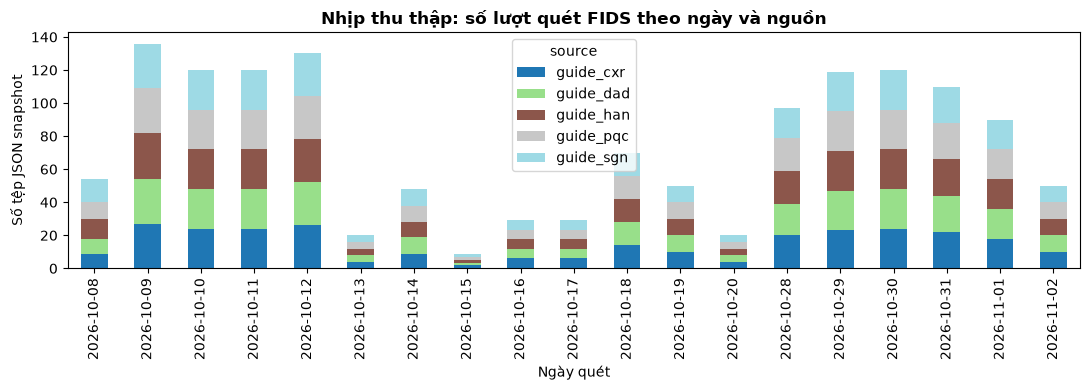

In [4]:
groups = {
    "Playwright: JSON bảng":    sorted((DEBUG_DIR / "playwright").glob("*.json")),
    "Playwright: HTML gốc":     sorted((DEBUG_DIR / "playwright" / "html").glob("*.html")),
    "Aviationstack: JSON gốc":  sorted((DEBUG_DIR / "aviationstack").glob("*.json")),
    "Open-Meteo: JSON gốc":     sorted((DEBUG_DIR / "open_meteo").glob("*.json")),
}
inv = []
for name, files in groups.items():
    ts = pd.Series([ts_from_name(p) for p in files], dtype="datetime64[ns]")
    inv.append({
        "Lớp bản gốc": name,
        "Số tệp": len(files),
        "Dung lượng (MB)": round(sum(p.stat().st_size for p in files) / 1e6, 2),
        "Thời điểm đầu": ts.min() if len(ts.dropna()) else "",
        "Thời điểm cuối": ts.max() if len(ts.dropna()) else "",
        "Số ngày khác nhau": ts.dt.date.nunique() if len(ts.dropna()) else 0,
    })
display(pd.DataFrame(inv))

if USAGE_FILE.exists():
    print("Hạn mức API đã dùng theo tháng (data/api_usage.json):")
    print(json.dumps(json.loads(USAGE_FILE.read_text(encoding="utf-8")), indent=1, ensure_ascii=False))

# Nhịp quét: số snapshot Playwright theo ngày và nguồn
pw_rows = []
for p in groups["Playwright: JSON bảng"]:
    m = re.match(r"^pw_(guide_[a-z]+)_(arrivals|departures)", p.stem)
    if m:
        pw_rows.append({"source": m.group(1), "direction": m.group(2), "date": ts_from_name(p).date()})
if pw_rows:
    pw_df = pd.DataFrame(pw_rows)
    cadence = pw_df.groupby(["date", "source"]).size().unstack(fill_value=0)
    fig, ax = plt.subplots(figsize=(11, 4))
    cadence.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
    ax.set_title("Nhịp thu thập: số lượt quét FIDS theo ngày và nguồn", fontweight="bold")
    ax.set_xlabel("Ngày quét")
    ax.set_ylabel("Số tệp JSON snapshot")
    plt.tight_layout()
    plt.show()
else:
    print("(Chưa có JSON snapshot Playwright dạng pw_<nguồn>_<hướng>_<thời gian>.json)")

### 2.4. Kiểm tra tính nguyên bản của bản gốc (Provenance Audit)
Vì yêu cầu là **CSV phải dựa trên JSON gốc**, trước khi dùng cần kiểm tra các tệp JSON có thực sự là phản hồi nguyên bản hay là tệp được dựng lại từ CSV cũ. Các dấu hiệu dưới đây là **heuristic** (nghi vấn, không phải bằng chứng tuyệt đối):

| Nguồn | Dấu hiệu nghi vấn |
| :--- | :--- |
| Aviationstack | số bản ghi **> `pagination.limit`** (một lần gọi không thể trả nhiều hơn `limit`); bản ghi **thiếu khóa `aircraft`/`live`** mà API gốc luôn có; `pagination.count` ≠ số bản ghi; nhiều tệp trùng **cùng một giây**. |
| Playwright | không có `tables` (định dạng phẳng đã parse sẵn); thiếu tham chiếu `html_file` hoặc tệp HTML tương ứng không tồn tại. |

In [5]:
def audit_aviationstack():
    rows = []
    for p in sorted((DEBUG_DIR / "aviationstack").glob("*.json")):
        rec = {"Tệp": p.name, "KB": round(p.stat().st_size / 1024, 1), "ts": ts_from_name(p)}
        flags = []
        try:
            d = json.loads(p.read_text(encoding="utf-8"))
        except Exception as e:
            rec["Nghi vấn"] = f"không đọc được JSON ({type(e).__name__})"
            rows.append(rec)
            continue
        if not isinstance(d, dict):
            flags.append("danh sách phẳng (đã parse)")
            data, pag = (d if isinstance(d, list) else []), {}
        else:
            data, pag = (d.get("data") or []), (d.get("pagination") or {})
            if "pagination" not in d:
                flags.append("không có pagination")
        limit, count = pag.get("limit"), pag.get("count")
        if limit and len(data) > int(limit):
            flags.append("số bản ghi > limit")
        if count is not None and str(count).isdigit() and int(count) != len(data):
            flags.append("count != số bản ghi")
        if data and not any(("aircraft" in r or "live" in r) for r in data if isinstance(r, dict)):
            flags.append("thiếu khóa aircraft/live")
        rec.update({"Số bản ghi": len(data), "limit": limit, "count": count, "Nghi vấn": "; ".join(flags)})
        rows.append(rec)
    out = pd.DataFrame(rows)
    if not out.empty:
        shared = out["ts"].duplicated(keep=False) & out["ts"].notna()
        out.loc[shared, "Nghi vấn"] = (out.loc[shared, "Nghi vấn"] + "; cùng giây với tệp khác").str.strip("; ")
    return out.drop(columns="ts") if not out.empty else out


def audit_playwright():
    rows = []
    html_dir = DEBUG_DIR / "playwright" / "html"
    for p in sorted((DEBUG_DIR / "playwright").glob("*.json")):
        rec = {"Tệp": p.name, "KB": round(p.stat().st_size / 1024, 1)}
        try:
            d = json.loads(p.read_text(encoding="utf-8"))
        except Exception as e:
            rec["Nghi vấn"] = f"không đọc được JSON ({type(e).__name__})"
            rows.append(rec)
            continue
        flags = []
        if isinstance(d, dict) and d.get("tables"):
            rec["Số bảng"] = len(d["tables"])
            rec["Số dòng bảng"] = sum(len(t.get("rows", [])) for t in d["tables"])
            hf = d.get("html_file", "")
            if not hf:
                flags.append("không ghi html_file")
            elif not (html_dir / hf).exists():
                flags.append("thiếu tệp HTML tương ứng")
        else:
            flags.append("không có tables (định dạng cũ, đã parse sẵn)")
        rec["Nghi vấn"] = "; ".join(flags)
        rows.append(rec)
    return pd.DataFrame(rows)


av_audit, pw_audit = audit_aviationstack(), audit_playwright()
for title, a in [("AVIATIONSTACK", av_audit), ("PLAYWRIGHT", pw_audit)]:
    print(f"=== KIỂM TRA TÍNH NGUYÊN BẢN: {title} ===")
    if a.empty:
        print("(không có tệp)\n")
        continue
    n_bad = int((a["Nghi vấn"] != "").sum())
    print(f"{len(a)} tệp | {len(a) - n_bad} tệp không có dấu hiệu nghi vấn | {n_bad} tệp có dấu hiệu nghi vấn")
    display(a[a["Nghi vấn"] != ""].head(20) if n_bad else a.head(5))

=== KIỂM TRA TÍNH NGUYÊN BẢN: AVIATIONSTACK ===
76 tệp | 52 tệp không có dấu hiệu nghi vấn | 24 tệp có dấu hiệu nghi vấn


,Tệp,KB,Số bản ghi,limit,count,Nghi vấn
13,aviationstack_BL_cancelled_20261009_191150.json,0.1,0,100,0,cùng giây với tệp khác
24,aviationstack_QH_cancelled_20261009_191149.json,0.1,0,100,0,cùng giây với tệp khác
32,aviationstack_QH_cancelled_20261031_000449.json,0.1,0,100,0,cùng giây với tệp khác
33,aviationstack_VJ_cancelled_20261010_191939.json,1.4,1,100,1,cùng giây với tệp khác
34,aviationstack_VJ_cancelled_20261011_202729.json,1.4,1,100,1,cùng giây với tệp khác
35,aviationstack_VJ_cancelled_20261028_062445.json,1.4,1,100,1,cùng giây với tệp khác
37,aviationstack_VJ_cancelled_20261031_000449.json,2.7,2,100,2,cùng giây với tệp khác
38,aviationstack_VJ_landed_20261009_191146.json,148.1,100,100,100,cùng giây với tệp khác
39,aviationstack_VJ_landed_20261009_191147.json,147.5,100,100,100,cùng giây với tệp khác
40,aviationstack_VJ_landed_20261009_191148.json,147.5,100,100,100,cùng giây với tệp khác


=== KIỂM TRA TÍNH NGUYÊN BẢN: PLAYWRIGHT ===
1421 tệp | 1421 tệp không có dấu hiệu nghi vấn | 0 tệp có dấu hiệu nghi vấn


,Tệp,KB,Số bảng,Số dòng bảng,Nghi vấn
0,pw_guide_cxr_arrivals_20261008_120524.json,6.5,1,38,
1,pw_guide_cxr_arrivals_20261008_142323.json,7.4,1,44,
2,pw_guide_cxr_arrivals_20261008_182326.json,5.4,1,31,
3,pw_guide_cxr_arrivals_20261008_202325.json,4.7,1,27,
4,pw_guide_cxr_arrivals_20261008_222325.json,4.0,1,23,


### 2.5. Truy vết một bản ghi qua các lớp: HTML → JSON → CSV thô → schema chuẩn
Phần này chọn **một tệp gốc mới nhất** của mỗi loại nguồn và cho thấy nó biến đổi như thế nào qua từng lớp. Mục đích là chứng minh chuỗi truy vết `source_file` hoạt động.

In [6]:
# ---------- A. Website sân bay: HTML -> JSON bảng -> bản ghi chuẩn ----------
pw_path, pw_json = None, None
for p in latest_first((DEBUG_DIR / "playwright").glob("*.json")):
    try:
        d = json.loads(p.read_text(encoding="utf-8"))
    except Exception:
        continue
    if isinstance(d, dict) and d.get("tables"):
        pw_path, pw_json = p, d
        break

if pw_json is None:
    print("(Chưa có JSON Playwright dạng bảng; chạy: python main.py collect)")
else:
    print(f"Tệp JSON bảng: {pw_path.name}")
    print({k: pw_json.get(k) for k in ["source", "airport", "direction", "scraped_at", "method", "table_count", "html_file"]})
    html_p = DEBUG_DIR / "playwright" / "html" / pw_json.get("html_file", "")
    if pw_json.get("html_file") and html_p.exists():
        html = html_p.read_text(encoding="utf-8", errors="ignore")
        i = html.find("<table")
        print(f"\n[LỚP 1a] HTML gốc: {html_p.name} ({len(html)/1024:.0f} KB). Đoạn đầu của thẻ <table>:")
        print(html[i:i + 450].replace("\n", " "), "...\n")
    t = pw_json["tables"][0]
    print(f"[LỚP 1b] JSON bảng #{t.get('table_index')}: tiêu đề = {t['headers']}")
    display(pd.DataFrame(t["rows"][:3], columns=t["headers"][:len(t["rows"][0])]))
    std_rows = collector.parse_guide_from_json(pw_json)
    print(f"[LỚP 3] Bản ghi chuẩn (12 cột) sau parse_guide_from_json: {len(std_rows)} dòng, 2 dòng đầu:")
    display(pd.DataFrame(std_rows[:2]))

# ---------- B. Aviationstack: JSON lồng nhau -> làm phẳng -> bản ghi chuẩn (2 phía) ----------
av_path, av_json = None, None
for p in latest_first((DEBUG_DIR / "aviationstack").glob("*.json")):
    try:
        d = json.loads(p.read_text(encoding="utf-8"))
    except Exception:
        continue
    if isinstance(d, dict) and d.get("data"):
        av_path, av_json = p, d
        break

if av_json is None:
    print("(Chưa có JSON Aviationstack; chạy: python main.py api)")
else:
    rec = av_json["data"][0]
    print(f"\nTệp JSON: {av_path.name} | pagination = {av_json.get('pagination')}")
    print("[LỚP 1] Bản ghi JSON nguyên bản (rút gọn):")
    print(json.dumps(rec, ensure_ascii=False, indent=1)[:1200])
    flat = collector.flatten_json(rec)
    print(f"\n[LỚP 2] Sau flatten_json: {len(flat)} cột, ví dụ:")
    display(pd.Series(flat).head(12).to_frame("giá trị"))
    ts_dt = ts_from_name(av_path)
    if pd.isna(ts_dt):                      # tên tệp không có dấu thời gian -> dùng thời điểm sửa tệp
        ts_dt = pd.Timestamp(av_path.stat().st_mtime, unit="s")
    ts_av = ts_dt.strftime("%Y-%m-%d %H:%M:%S")
    print("[LỚP 3] 1 bản ghi API tách thành 2 bản ghi chuẩn (phía khởi hành và phía đến):")
    display(pd.DataFrame(collector.parse_aviationstack_json({"data": [rec]}, scraped_at=ts_av)))

Tệp JSON bảng: pw_guide_pqc_departures_20261102_091131.json
{'source': 'guide_pqc', 'airport': 'PQC', 'direction': 'departures', 'scraped_at': '2026-11-02 09:11:03', 'method': 'playwright', 'table_count': 1, 'html_file': 'pw_guide_pqc_departures_20261102_091130.html'}

[LỚP 1a] HTML gốc: pw_guide_pqc_departures_20261102_091130.html (48 KB). Đoạn đầu của thẻ <table>:
<table class="c-flight-status-table"><thead><tr><th width="10%">Scheduled</th><th width="10%">Revised</th><th width="25%">To</th><th width="30%">Flight</th><th width="20%">Status</th></tr></thead><tbody><tr><td data-label="Scheduled">07:35</td><td data-label="Revised">07:35</td><td data-label="To">Hanoi (HAN)</td><td data-label="Flight">VietJet Air VJC 448</td><td data-label="Status" class="c-flight-status-table__status">On-Time</td></tr><tr><td  ...

[LỚP 1b] JSON bảng #0: tiêu đề = ['Scheduled', 'Revised', 'To', 'Flight', 'Status']


,Scheduled,Revised,To,Flight,Status
0,07:35,07:35,Hanoi (HAN),VietJet Air VJC 448,On-Time
1,07:40,07:40,Ho Chi Minh City (SGN),Sun PhuQuoc Airways 9G 1952,Departed On-Time
2,08:20,08:22,Hanoi (HAN),Sun PhuQuoc Airways 9G 1202,Departed On-Time


[LỚP 3] Bản ghi chuẩn (12 cột) sau parse_guide_from_json: 40 dòng, 2 dòng đầu:


,source,airport,direction,scraped_at,flight_date,airline_code,flight_no,other_airport,scheduled_time,estimated_time,actual_time,status
0,guide_pqc,PQC,departures,2026-11-02 09:11:03,2026-11-02,VJ,VJ448,Hanoi (HAN),07:35,07:35,,On-Time
1,guide_pqc,PQC,departures,2026-11-02 09:11:03,2026-11-02,9G,9G1952,Ho Chi Minh City (SGN),07:40,07:40,07:40,Departed On-Time



Tệp JSON: aviationstack_VJ_landed_20261031_000455.json | pagination = {'limit': 100, 'offset': 0, 'count': 100, 'total': 461}
[LỚP 1] Bản ghi JSON nguyên bản (rút gọn):
{
 "flight_date": "2026-10-30",
 "flight_status": "landed",
 "departure": {
  "airport": "Phu Bai",
  "timezone": "Asia/Ho_Chi_Minh",
  "iata": "HUI",
  "icao": "VVPB",
  "terminal": null,
  "gate": null,
  "delay": 3,
  "scheduled": "2026-10-30T21:30:00+00:00",
  "estimated": "2026-10-30T21:30:00+00:00",
  "actual": "2026-10-30T21:33:00+00:00",
  "estimated_runway": "2026-10-30T21:33:00+00:00",
  "actual_runway": "2026-10-30T21:33:00+00:00"
 },
 "arrival": {
  "airport": "Tan Son Nhat International",
  "timezone": "Asia/Ho_Chi_Minh",
  "iata": "SGN",
  "icao": "VVTS",
  "terminal": "1",
  "gate": null,
  "baggage": null,
  "scheduled": "2026-10-30T22:55:00+00:00",
  "delay": 0,
  "estimated": "2026-10-30T22:39:00+00:00",
  "actual": "2026-10-30T22:37:00+00:00",
  "estimated_runway": "2026-10-30T22:37:00+00:00",
  "act

,giá trị
flight_date,2026-10-30
flight_status,landed
departure.airport,Phu Bai
departure.timezone,Asia/Ho_Chi_Minh
departure.iata,HUI
departure.icao,VVPB
departure.terminal,
departure.gate,
departure.delay,3
departure.scheduled,2026-10-30T21:30:00+00:00


[LỚP 3] 1 bản ghi API tách thành 2 bản ghi chuẩn (phía khởi hành và phía đến):


,source,airport,direction,scraped_at,flight_date,airline_code,flight_no,other_airport,scheduled_time,estimated_time,actual_time,status
0,aviationstack_api,HUI,departures,2026-10-31 00:04:55,2026-10-30,VJ,VJ313,SGN,21:30,21:30,21:33,Departed 3 minutes late
1,aviationstack_api,SGN,arrivals,2026-10-31 00:04:55,2026-10-30,VJ,VJ313,HUI,22:55,22:39,22:37,Arrived On-Time


### 2.6. Lớp CSV thô: mỗi nguồn giữ cột riêng
`rebuild_raw_csv()` đọc toàn bộ JSON gốc và **làm phẳng** thành `data/raw/<nguồn>_<YYYYMM>.csv`:
- **`aviationstack_api_*.csv`:** mỗi bản ghi API là một dòng; cột là đường dẫn khóa JSON (`departure.iata`, `departure.delay`, `airline.name`, `flight.codeshared.*`, ...). Các cột `terminal`, `gate` vẫn được giữ ở lớp thô.
- **`guide_<sân bay>_*.csv`:** mỗi dòng bảng HTML là một dòng; cột là **đúng tiêu đề bảng** (`Scheduled`, `Revised`, `Flight`, `From`/`To`, `Status`). Bảng không phải bảng chuyến bay bị bỏ qua.
- Mọi tệp đều có `scraped_at` và `source_file` (tên JSON gốc) để truy vết.
- Việc **bỏ cột và quy chuẩn về 12 cột nằm ở bước tích hợp** (Phần 3), không phải ở lớp thô.

In [7]:
n_rows = collector.rebuild_raw_csv()
print(f"Đã dựng lại data/raw từ JSON gốc: {n_rows:,} dòng\n")

raw_files = sorted(RAW_DIR.glob("*.csv"))
raw_info, raw_cols = [], {}
for f in raw_files:
    d = pd.read_csv(f, dtype=str, keep_default_na=False)
    raw_cols[f.name] = list(d.columns)
    raw_info.append({"Tệp CSV thô": f.name, "Số dòng": len(d), "Số cột": d.shape[1],
                     "Số JSON nguồn": d["source_file"].nunique() if "source_file" in d else ""})
display(pd.DataFrame(raw_info))

av_cols = next((c for n, c in raw_cols.items() if n.startswith("aviationstack")), [])
gd_cols = next((c for n, c in raw_cols.items() if n.startswith("guide") and "_legacy_" not in n), [])
print("Cột lớp thô của Aviationstack:", av_cols[:14], "..." if len(av_cols) > 14 else "")
print("Cột lớp thô của bảng FIDS     :", gd_cols)
print(f"\nSố cột chung giữa hai nguồn: {sorted(set(av_cols) & set(gd_cols))}")
print("=> Hai nguồn có cột khác nhau; chỉ gặp nhau ở schema chuẩn 12 cột (bước tích hợp).")

Đã dựng lại data/raw từ JSON gốc: 92,146 dòng



,Tệp CSV thô,Số dòng,Số cột,Số JSON nguồn
0,aviationstack_api_202610.csv,1450,48,32
1,guide_cxr_202610.csv,8653,12,254
2,guide_cxr_202611.csv,976,12,28
3,guide_dad_202610.csv,12168,12,254
4,guide_dad_202611.csv,1642,12,28
5,guide_han_202610.csv,23073,12,259
6,guide_han_202611.csv,5208,12,28
7,guide_pqc_202610.csv,8912,12,255
8,guide_pqc_202611.csv,1051,12,28
9,guide_sgn_202610.csv,23455,12,259


Cột lớp thô của Aviationstack: ['scraped_at', 'source_file', 'flight_date', 'flight_status', 'departure.airport', 'departure.timezone', 'departure.iata', 'departure.icao', 'departure.terminal', 'departure.gate', 'departure.delay', 'departure.scheduled', 'departure.estimated', 'departure.actual'] ...
Cột lớp thô của bảng FIDS     : ['source', 'airport', 'direction', 'scraped_at', 'table_index', 'source_file', 'Scheduled', 'Revised', 'From', 'Flight', 'Status', 'To']

Số cột chung giữa hai nguồn: ['scraped_at', 'source_file']
=> Hai nguồn có cột khác nhau; chỉ gặp nhau ở schema chuẩn 12 cột (bước tích hợp).


### 2.7. Tổng kết Bước 1: dữ liệu sau khi đưa về schema chuẩn 12 cột
`load_standard_records()` chuyển CSV thô của **từng nguồn** về cùng schema `FIELDS`. Đây là điểm bắt đầu của Bước 2.

Tổng snapshot sau tích hợp: 93,081 dòng x 12 cột | số nguồn: 6
Cột: ['source', 'airport', 'direction', 'scraped_at', 'flight_date', 'airline_code', 'flight_no', 'other_airport', 'scheduled_time', 'estimated_time', 'actual_time', 'status'] 



,Snapshot,Chuyen_khac_nhau,Ngay_dau,Ngay_cuoi,So_lan_quet,Ty_trong_%
source,,,,,,
guide_sgn,29011,1082,2026-10-08,2026-11-02,144,31.17
guide_han,28281,900,2026-10-08,2026-11-02,144,30.38
guide_dad,13810,424,2026-10-08,2026-11-02,143,14.84
guide_pqc,9960,247,2026-10-08,2026-11-02,143,10.70
guide_cxr,9629,210,2026-10-08,2026-11-02,143,10.34
aviationstack_api,2390,743,2026-10-08,2026-10-30,21,2.57


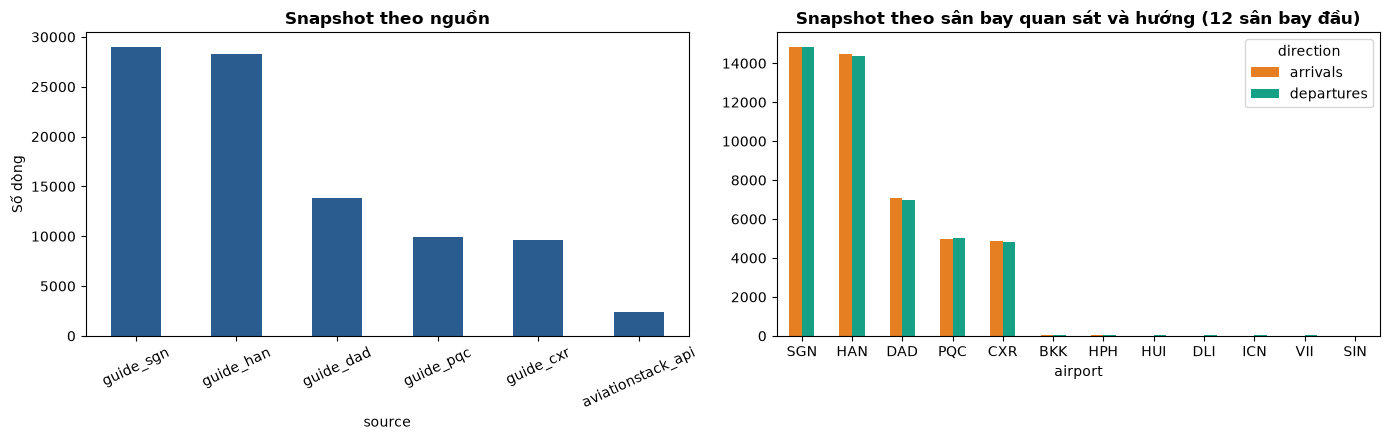

In [8]:
df_std = collector.load_standard_records()
print(f"Tổng snapshot sau tích hợp: {len(df_std):,} dòng x {df_std.shape[1]} cột | số nguồn: {df_std['source'].nunique()}")
print("Cột:", list(df_std.columns), "\n")

by_src = df_std.groupby("source").agg(
    Snapshot=("flight_no", "count"),
    Chuyen_khac_nhau=("flight_no", "nunique"),
    Ngay_dau=("flight_date", "min"),
    Ngay_cuoi=("flight_date", "max"),
    So_lan_quet=("scraped_at", "nunique"),
).sort_values("Snapshot", ascending=False)
by_src["Ty_trong_%"] = (by_src["Snapshot"] / len(df_std) * 100).round(2)
display(by_src)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_src["Snapshot"].plot(kind="bar", ax=axes[0], color="#2b5c8f")
axes[0].set_title("Snapshot theo nguồn", fontweight="bold")
axes[0].set_ylabel("Số dòng")
axes[0].tick_params(axis="x", rotation=25)
ap = df_std.groupby(["airport", "direction"]).size().unstack(fill_value=0)
ap = ap.loc[ap.sum(axis=1).sort_values(ascending=False).head(12).index]
ap.plot(kind="bar", ax=axes[1], color=["#e67e22", "#16a085"])
axes[1].set_title("Snapshot theo sân bay quan sát và hướng (12 sân bay đầu)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 3. BƯỚC 2: TIỀN XỬ LÝ DỮ LIỆU (Data Preprocessing)

### 3.0. Các vấn đề chất lượng và chiến lược xử lý

| # | Vấn đề | Nguyên nhân | Chiến lược (hàm trong `processor.py`) |
| :-: | :--- | :--- | :--- |
| 1 | **Trùng lặp theo thời gian** | Quét 120 phút/lượt nên một chuyến xuất hiện nhiều lần | Khử trùng cùng phía theo khóa `K1`, giữ bản ghi nhiều thông tin và mới nhất |
| 2 | **Một chuyến thấy ở hai đầu** | Có trong bảng đi tại sân bay A và bảng đến tại sân bay B | Khóa `leg_key` → một dòng/chuyến |
| 3 | **Tên sân bay không chuẩn** | Trang web ghi `Ho Chi Minh City`, `Hanoi`, `Tokyo (NRT)`... | `to_iata()` (regex + từ điển `CITY_IATA`) |
| 4 | **Số hiệu chuyến không đồng nhất** | `VJ 0123` so với `VJ123`, khoảng trắng | `normalize_flight_no()` |
| 5 | **`actual_time` trống dù chuyến đã hoàn tất** | Bảng chỉ có cột `Revised` | Điền từ `estimated_time` khi trạng thái là đã bay/hạ cánh |
| 6 | **Độ trễ qua nửa đêm** | `23:50` → `00:10` cho kết quả -1420 phút | `calculate_delay()` cộng/trừ 1440 phút |
| 7 | **Ngoại lai nhiễu** | Chuyến "bay sớm" hơn 90 phút so với lịch | Gán `unknown` và loại khỏi khai phá (`EARLY_LIMIT = -90`) |
| 8 | **Cột thiếu nhiều** | `terminal`, `gate`, `extra` hầu như trống | Loại khỏi schema (ngưỡng cảnh báo `MISSING_WARN = 40%`) |
| 9 | **Hãng ngoài phạm vi, chuyến codeshare** | API/FIDS trả mọi hãng, kể cả chuyến liên danh | Lọc `VN_AIRLINES`; bỏ chuyến `codeshared` khi tích hợp Aviationstack |

### 3.1. Khảo sát chất lượng trên tập chuẩn 12 cột (Bảng 1)

In [9]:
empty_cnt = (df_std == "").sum()
quality_report = pd.DataFrame({
    "Trường": df_std.columns,
    "Số dòng trống": empty_cnt.values,
    "Tỷ lệ trống (%)": (empty_cnt / len(df_std) * 100).round(2).values,
    "Số giá trị khác nhau": [df_std[c].nunique() for c in df_std.columns],
    "Giá trị mẫu": [df_std.loc[df_std[c] != "", c].iloc[0] if (df_std[c] != "").any() else "(trống hoàn toàn)"
                    for c in df_std.columns],
})
print("=== BẢNG 1: CHẤT LƯỢNG CỘT VÀ TỶ LỆ TRỐNG TRÊN TẬP CHUẨN (12 CỘT) ===")
display(quality_report)

done_re = r"arrive|depart|land|hacan|catcan"
is_done = df_std["status"].str.contains(done_re, case=False, regex=True, na=False)
checks = [
    ("other_airport chưa phải mã IATA 3 chữ cái (vd. 'Ho Chi Minh City')",
     ~df_std["other_airport"].str.fullmatch(r"[A-Z]{3}"), "to_iata(): regex '(XXX)' + từ điển CITY_IATA"),
    ("airline_code trống (không suy ra được từ tên hãng)",
     df_std["airline_code"] == "", "Loại khi lọc hãng Việt Nam"),
    ("flight_no sai định dạng 2 ký tự hãng + 1-4 chữ số",
     ~df_std["flight_no"].str.upper().str.replace(r"\s+", "", regex=True).str.fullmatch(r"[A-Z0-9]{2}\d{1,4}"),
     "normalize_flight_no(): bỏ khoảng trắng, bỏ số 0 đầu"),
    ("scheduled_time không phải HH:MM",
     ~df_std["scheduled_time"].str.fullmatch(r"\d{1,2}:\d{2}"), "Không tính được giờ bay -> thiếu time_slot/thời tiết"),
    ("status trống", df_std["status"] == "", "Không gán được nhãn -> unknown"),
    ("direction viết thường ('arrivals'/'departures')",
     df_std["direction"] != df_std["direction"].str.upper(), "Chuẩn hóa .upper() ở prepare_dataset()"),
    ("Chuyến đã hoàn tất nhưng actual_time trống",
     is_done & (df_std["actual_time"] == ""), "Điền từ estimated_time nếu có"),
]
mismatch = pd.DataFrame([{
    "Loại bất thường": name, "Số dòng": int(mask.sum()), "Tỷ lệ (%)": round(mask.mean() * 100, 2), "Cách xử lý": fix,
} for name, mask, fix in checks])
print("\n=== BẢNG 2: BẤT THƯỜNG ĐỊNH DẠNG VÀ CÁCH QUY CHUẨN ===")
display(mismatch)

=== BẢNG 1: CHẤT LƯỢNG CỘT VÀ TỶ LỆ TRỐNG TRÊN TẬP CHUẨN (12 CỘT) ===


,Trường,Số dòng trống,Tỷ lệ trống (%),Số giá trị khác nhau,Giá trị mẫu
0,source,0,0.00,6,aviationstack_api
1,airport,0,0.00,73,SGN
2,direction,0,0.00,2,departures
3,scraped_at,0,0.00,166,2026-10-09 19:04:34
4,flight_date,0,0.00,20,2026-10-09
5,airline_code,3526,3.79,66,VN
6,flight_no,0,0.00,2250,VN6160
7,other_airport,0,0.00,194,HUI
8,scheduled_time,0,0.00,290,16:05
9,estimated_time,320,0.34,1417,16:05



=== BẢNG 2: BẤT THƯỜNG ĐỊNH DẠNG VÀ CÁCH QUY CHUẨN ===


,Loại bất thường,Số dòng,Tỷ lệ (%),Cách xử lý
0,other_airport chưa phải mã IATA 3 chữ cái (vd. 'Ho Chi Minh City'),90691,97.43,to_iata(): regex '(XXX)' + từ điển CITY_IATA
1,airline_code trống (không suy ra được từ tên hãng),3526,3.79,Loại khi lọc hãng Việt Nam
2,flight_no sai định dạng 2 ký tự hãng + 1-4 chữ số,3526,3.79,"normalize_flight_no(): bỏ khoảng trắng, bỏ số 0 đầu"
3,scheduled_time không phải HH:MM,37,0.04,Không tính được giờ bay -> thiếu time_slot/thời tiết
4,status trống,0,0.00,Không gán được nhãn -> unknown
5,direction viết thường ('arrivals'/'departures'),93081,100.00,Chuẩn hóa .upper() ở prepare_dataset()
6,Chuyến đã hoàn tất nhưng actual_time trống,14,0.02,Điền từ estimated_time nếu có


### 3.2. Kiểm thử các quy tắc làm sạch trên ví dụ nhỏ
Các bảng dưới gọi **trực tiếp hàm thật** của `processor.py` trên đầu vào dựng tay để minh họa quy tắc. Đây cũng là bộ "unit test" mô tả hành vi mong đợi.

**Công thức độ trễ** (`calculate_delay`): với `S` = giờ lịch, `T` = giờ thực tế (nếu trống thì lấy giờ dự kiến), tính theo phút trong ngày:

$$\text{delay} = T - S, \qquad \text{nếu } \text{delay} < -720 \Rightarrow +1440, \quad \text{nếu } \text{delay} > 720 \Rightarrow -1440$$

Nếu trạng thái đã ghi sẵn `N minutes late` / `Delayed N minutes` / `N minutes early` thì dùng số `N` đó.

In [10]:
# --- Độ trễ ---
cases = [
    ("23:50", "", "00:10", "", "Bay qua nửa đêm (trễ 20 phút)"),
    ("00:10", "", "23:50", "", "Bay sớm qua nửa đêm (-20 phút)"),
    ("10:00", "", "10:35", "", "Tính từ giờ thực tế"),
    ("10:00", "10:40", "", "", "Không có giờ thực tế -> dùng giờ dự kiến"),
    ("10:00", "", "", "Departed 12 minutes late", "Số phút đã ghi sẵn trong trạng thái"),
    ("10:00", "", "", "Delayed 30 minutes", "Chưa bay nhưng báo trễ"),
    ("10:00", "", "", "Arrived 5 minutes early", "Đến sớm"),
    ("10:00", "", "", "Scheduled", "Không có thông tin để tính"),
]
display(pd.DataFrame([{
    "scheduled": s, "estimated": e, "actual": a, "status": st, "Ý nghĩa": note,
    "delay_min": processor.calculate_delay(s, e, a, st),
} for s, e, a, st, note in cases]))

# --- Chuẩn hóa số hiệu chuyến và mã sân bay ---
fn = pd.Series(["VJ 0123", "VN 0007", "QH201", "VU  45"])
display(pd.DataFrame({"flight_no gốc": fn, "sau chuẩn hóa": processor.normalize_flight_no(fn)}))
names = ["Ho Chi Minh City (SGN)", "HAN", "Hanoi", "Da Nang", "Phu Quoc", "Tokyo (NRT)", "Bangkok"]
display(pd.DataFrame({"other_airport gốc": names, "to_iata()": [processor.to_iata(n) or "(không nhận ra)" for n in names]}))

,scheduled,estimated,actual,status,Ý nghĩa,delay_min
0,23:50,,00:10,,Bay qua nửa đêm (trễ 20 phút),20.0
1,00:10,,23:50,,Bay sớm qua nửa đêm (-20 phút),-20.0
2,10:00,,10:35,,Tính từ giờ thực tế,35.0
3,10:00,10:40,,,Không có giờ thực tế -> dùng giờ dự kiến,40.0
4,10:00,,,Departed 12 minutes late,Số phút đã ghi sẵn trong trạng thái,12.0
5,10:00,,,Delayed 30 minutes,Chưa bay nhưng báo trễ,30.0
6,10:00,,,Arrived 5 minutes early,Đến sớm,-5.0
7,10:00,,,Scheduled,Không có thông tin để tính,NaN


,flight_no gốc,sau chuẩn hóa
0,VJ 0123,VJ123
1,VN 0007,VN7
2,QH201,QH201
3,VU 45,VU45


,other_airport gốc,to_iata()
0,Ho Chi Minh City (SGN),SGN
1,HAN,HAN
2,Hanoi,HAN
3,Da Nang,DAD
4,Phu Quoc,PQC
5,Tokyo (NRT),NRT
6,Bangkok,(không nhận ra)


In [11]:
# --- Gán nhãn trên ví dụ dựng tay (ngưỡng 15 phút và 30 phút) ---
label_cases = [
    {"status": "Departed", "direction": "DEPARTURES", "delay_min": np.nan, "actual_time": ""},
    {"status": "Departed 5 minutes late", "direction": "DEPARTURES", "delay_min": 5, "actual_time": "10:05"},
    {"status": "Departed 20 minutes late", "direction": "DEPARTURES", "delay_min": 20, "actual_time": "10:20"},
    {"status": "Arrived 25 minutes late", "direction": "ARRIVALS", "delay_min": 25, "actual_time": "10:25"},
    {"status": "Arrived On-Time", "direction": "ARRIVALS", "delay_min": 0, "actual_time": "10:00"},
    {"status": "Delayed 40 minutes", "direction": "DEPARTURES", "delay_min": 40, "actual_time": ""},
    {"status": "Cancelled", "direction": "DEPARTURES", "delay_min": np.nan, "actual_time": ""},
    {"status": "Scheduled", "direction": "ARRIVALS", "delay_min": np.nan, "actual_time": ""},
    {"status": "Diverted", "direction": "ARRIVALS", "delay_min": np.nan, "actual_time": ""},
    {"status": "Departed", "direction": "DEPARTURES", "delay_min": -120, "actual_time": "08:00"},
    {"status": "", "direction": "ARRIVALS", "delay_min": 2, "actual_time": "10:02"},
]
out = []
for c in label_cases:
    s15, d15, y15 = processor.label_status(c, 15)
    _, _, y30 = processor.label_status(c, 30)
    out.append({"status gốc": c["status"] or "(trống)", "hướng": c["direction"], "delay_min": c["delay_min"],
                "status chuẩn": s15, "status_detail": d15, "nhãn (15')": y15, "nhãn (30')": y30})
print("Bảng ví dụ gán nhãn: 'Departed' trơn không có giờ -> unknown (không đoán là đúng giờ); bay sớm > 90 phút -> unknown.")
display(pd.DataFrame(out))

Bảng ví dụ gán nhãn: 'Departed' trơn không có giờ -> unknown (không đoán là đúng giờ); bay sớm > 90 phút -> unknown.


,status gốc,hướng,delay_min,status chuẩn,status_detail,nhãn (15'),nhãn (30')
0,Departed,DEPARTURES,NaN,Departed,unknown,unknown,unknown
1,Departed 5 minutes late,DEPARTURES,5.0,Departed On-Time,departed_on_time,on_time,on_time
2,Departed 20 minutes late,DEPARTURES,20.0,Departed 20 minutes late,departed_late,delayed,on_time
3,Arrived 25 minutes late,ARRIVALS,25.0,Arrived 25 minutes late,arrived_late,delayed,on_time
4,Arrived On-Time,ARRIVALS,0.0,Arrived On-Time,arrived_on_time,on_time,on_time
5,Delayed 40 minutes,DEPARTURES,40.0,Delayed 40 minutes,delayed,delayed,delayed
6,Cancelled,DEPARTURES,NaN,Cancelled,cancelled,cancelled,cancelled
7,Scheduled,ARRIVALS,NaN,Scheduled,scheduled,unknown,unknown
8,Diverted,ARRIVALS,NaN,Diverted,diverted,unknown,unknown
9,Departed,DEPARTURES,-120.0,Departed,unknown,unknown,unknown


### 3.3. Khử trùng đa cấp bằng hàm băm SHA-256
Ba cấp khử trùng được định lượng bằng cách băm khóa định danh (SHA-256, lấy 16 ký tự đầu):

1. **Cấp 0 (dòng trùng tuyệt đối):** toàn bộ 12 cột giống nhau.
2. **Cấp 1 (khóa sự kiện cùng phía `K1`):** `SHA256(airport | direction | flight_date | flight_no | scheduled_time)`. Gộp các snapshot lặp lại của cùng một sự kiện tại cùng một sân bay, giữ bản ghi **nhiều thông tin nhất và mới nhất** (`has_info`, `has_done_act`, `scraped_at`).
3. **Cấp 2 (khóa chuyến `leg_key`):** `SHA256(flight_no | flight_date | origin>destination)`. Gộp bản ghi **cất cánh ở A** và bản ghi **hạ cánh ở B** của cùng một chuyến thành một dòng. Khi cả hai phía đều có dữ liệu, ưu tiên phía ở sân bay được theo dõi (có thời tiết) rồi phía khởi hành.

Sau đó kết quả được **đối chiếu chéo** với số liệu mà `prepare_dataset()` tự báo cáo.

=== BẢNG 3: KẾT QUẢ KHỬ TRÙNG ĐA CẤP (SHA-256) ===


,Bước,Số dòng,Loại bỏ so với bước trước,Còn lại so với thô (%)
0,Snapshot thô (sau tích hợp),93081,0,100.00
1,Cấp 0: sau bỏ dòng trùng tuyệt đối,93071,10,99.99
2,Sau lọc hãng Việt Nam,68250,24821,73.32
3,Cấp 1: sau khử trùng cùng phía (K1),19387,48863,20.83
4,Cấp 2: sau khử trùng cấp chuyến (leg_key),13610,5777,14.62


Đối chiếu với báo cáo của processor.prepare_dataset():
  Sau khử trùng cùng phía : băm = 19,387 | processor = 19,387 | khớp: True
  Sau khử trùng cấp chuyến: băm = 13,610 | processor = 13,610 | khớp: True
  Chuyến thấy ở cả bảng đi và bảng đến : 5,264
  Sự kiện được ghi nhận bởi >= 2 nguồn : 800
  Bản ghi không ghép được khóa cấp chuyến (other_airport lạ): 0


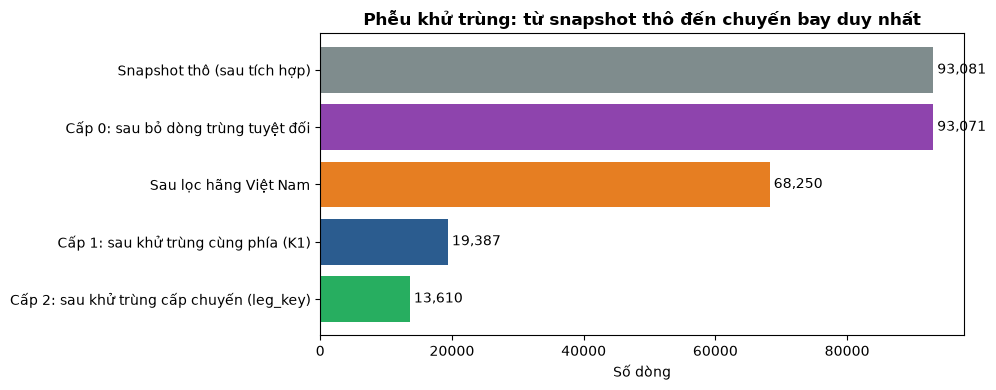

In [12]:
# prepare_dataset(): chuỗi tiền xử lý đầy đủ -> side (cùng phía), leg (cấp chuyến), stats, per_src (theo nguồn)
side, leg, stats, per_src = processor.prepare_dataset()

# ---- Tính lại bằng hàm băm độc lập để đối chiếu ----
df_n = df_std.copy()
for c in ["airport", "direction", "flight_date", "flight_no", "scheduled_time", "airline_code"]:
    df_n[c] = df_n[c].astype(str).str.strip().str.upper()
df_n["flight_no"] = processor.normalize_flight_no(df_n["flight_no"])

def sha(x):
    return hashlib.sha256(x.encode("utf-8")).hexdigest()[:16]

n_snap = len(df_n)
n_exact = len(df_n.drop_duplicates())
df_vn = df_n[df_n["airline_code"].isin(VN_AIRLINES)].copy()
n_vn = len(df_vn)
df_vn = processor.add_leg_key(df_vn)
df_vn["k1_hash"] = df_vn[processor.K1].agg("|".join, axis=1).map(sha)
df_vn["leg_hash"] = df_vn["leg_key"].map(sha)
n_k1, n_leg = df_vn["k1_hash"].nunique(), df_vn["leg_hash"].nunique()

funnel = pd.DataFrame([
    ("Snapshot thô (sau tích hợp)",                         n_snap),
    ("Cấp 0: sau bỏ dòng trùng tuyệt đối",                  n_exact),
    ("Sau lọc hãng Việt Nam",                               n_vn),
    ("Cấp 1: sau khử trùng cùng phía (K1)",                 n_k1),
    ("Cấp 2: sau khử trùng cấp chuyến (leg_key)",           n_leg),
], columns=["Bước", "Số dòng"])
funnel["Loại bỏ so với bước trước"] = (-funnel["Số dòng"].diff()).fillna(0).astype(int)
funnel["Còn lại so với thô (%)"] = (funnel["Số dòng"] / n_snap * 100).round(2)
print("=== BẢNG 3: KẾT QUẢ KHỬ TRÙNG ĐA CẤP (SHA-256) ===")
display(funnel)

print("Đối chiếu với báo cáo của processor.prepare_dataset():")
print(f"  Sau khử trùng cùng phía : băm = {n_k1:,} | processor = {stats['after_side_dedup']:,} | khớp: {n_k1 == stats['after_side_dedup']}")
print(f"  Sau khử trùng cấp chuyến: băm = {n_leg:,} | processor = {stats['after_leg_dedup']:,} | khớp: {n_leg == stats['after_leg_dedup']}")
print(f"  Chuyến thấy ở cả bảng đi và bảng đến : {stats['legs_seen_both_sides']:,}")
print(f"  Sự kiện được ghi nhận bởi >= 2 nguồn : {int((leg['source_recorded_count'] > 1).sum()):,}")
print(f"  Bản ghi không ghép được khóa cấp chuyến (other_airport lạ): {stats['unmatched_side']:,}")
if stats["unmatched_side"]:
    print("  Giá trị other_airport hay gặp nhất chưa nhận ra (bổ sung vào CITY_IATA nếu cần):")
    print(stats["unmapped_top"].head(8).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(funnel["Bước"][::-1], funnel["Số dòng"][::-1], color=["#27ae60", "#2b5c8f", "#e67e22", "#8e44ad", "#7f8c8d"])
for i, v in enumerate(funnel["Số dòng"][::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_title("Phễu khử trùng: từ snapshot thô đến chuyến bay duy nhất", fontweight="bold")
ax.set_xlabel("Số dòng")
plt.tight_layout()
plt.show()

### 3.4. Xử lý giá trị thiếu và quyết định loại cột
**Quy tắc:** cột có tỷ lệ thiếu **> 40%** (`MISSING_WARN`) bị cân nhắc loại khỏi schema, vì không đủ thông tin để khai phá. Quy tắc này áp dụng nhất quán cho `terminal`, `gate`, `extra` (đã bị loại khỏi `FIELDS`; ghi chú trong `config.py`: khuyết thiếu 63%–99%) và cho cột thời tiết của sân bay phía bên kia (`other_precipitation`).

Hai ô dưới (a) đo tỷ lệ thiếu của các cột liên quan **ngay trên lớp thô của Aviationstack**, (b) đo tỷ lệ thiếu của cột `Revised`/`Status` ở bảng FIDS, và (c) đếm số dòng được **điền `actual_time`** từ `estimated_time`.

In [13]:
# (a) Cột liên quan của Aviationstack ở lớp thô: tỷ lệ trống và quyết định theo ngưỡng 40%
av_files = sorted(RAW_DIR.glob("aviationstack_api_*.csv"))
if av_files:
    av = pd.concat([pd.read_csv(f, dtype=str, keep_default_na=False) for f in av_files], ignore_index=True)
    miss_av = (av == "").mean().mul(100).round(1).sort_values(ascending=False)
    keys = ("terminal", "gate", "baggage", "actual", "estimated", "delay", "runway")
    focus = miss_av[[c for c in miss_av.index if any(k in c for k in keys)]]
    tbl = pd.DataFrame({"Cột lớp thô (Aviationstack)": focus.index, "Tỷ lệ trống (%)": focus.values})
    tbl["Quyết định"] = np.where(tbl["Tỷ lệ trống (%)"] > processor.MISSING_WARN, "LOẠI (thiếu > 40%)", "Giữ / dùng để suy ra cột khác")
    print(f"(a) Aviationstack lớp thô: {len(av):,} bản ghi")
    display(tbl)
else:
    print("(a) Chưa có CSV thô Aviationstack.")

# (b) Bảng FIDS: cột Revised / Status
gfiles = [f for f in sorted(RAW_DIR.glob("guide_*.csv")) if "_legacy_" not in f.name]
if gfiles:
    gd = pd.concat([pd.read_csv(f, dtype=str, keep_default_na=False) for f in gfiles], ignore_index=True)
    rows = []
    for col in ["Scheduled", "Revised", "Status"]:
        if col in gd.columns:
            rows.append({"Cột bảng FIDS": col, "Tỷ lệ trống (%)": round((gd[col] == "").mean() * 100, 2)})
    print("\n(b) Bảng FIDS lớp thô:", f"{len(gd):,} dòng")
    display(pd.DataFrame(rows))

# (c) Điền actual_time cho chuyến đã hoàn tất
fill_mask = is_done & (df_std["actual_time"] == "") & (df_std["estimated_time"] != "")
print(f"\n(c) Số dòng đã hoàn tất, actual_time trống nhưng có estimated_time -> được điền: {int(fill_mask.sum()):,} "
      f"({fill_mask.mean() * 100:.2f}% tổng snapshot)")

(a) Aviationstack lớp thô: 1,450 bản ghi


,Cột lớp thô (Aviationstack),Tỷ lệ trống (%),Quyết định
0,arrival.baggage,94.7,LOẠI (thiếu > 40%)
1,arrival.gate,89.9,LOẠI (thiếu > 40%)
2,departure.gate,74.2,LOẠI (thiếu > 40%)
3,departure.terminal,32.7,Giữ / dùng để suy ra cột khác
4,arrival.actual_runway,30.4,Giữ / dùng để suy ra cột khác
5,arrival.estimated_runway,30.1,Giữ / dùng để suy ra cột khác
6,departure.actual_runway,28.8,Giữ / dùng để suy ra cột khác
7,arrival.estimated,28.6,Giữ / dùng để suy ra cột khác
8,departure.estimated_runway,28.5,Giữ / dùng để suy ra cột khác
9,arrival.actual,28.4,Giữ / dùng để suy ra cột khác



(b) Bảng FIDS lớp thô: 90,696 dòng


,Cột bảng FIDS,Tỷ lệ trống (%)
0,Scheduled,0.0
1,Revised,0.0
2,Status,0.0



(c) Số dòng đã hoàn tất, actual_time trống nhưng có estimated_time -> được điền: 0 (0.00% tổng snapshot)


### 3.5. Phát hiện và xử lý ngoại lai (Outliers)
- **Phương pháp IQR:** $\text{IQR} = Q_3 - Q_1$; ngưỡng $[Q_1 - 1.5\,\text{IQR},\ Q_3 + 1.5\,\text{IQR}]$.
- Trong hàng không, chuyến trễ rất lâu là **trễ vận hành thực tế**, không phải lỗi dữ liệu, nên **không xóa** chỉ vì nằm ngoài IQR. Chỉ xử lý hai loại là *lỗi định dạng/nhiễu*:

| Loại | Dấu hiệu | Xử lý |
| :--- | :--- | :--- |
| Lệch vòng ngày | `abs(T - S) > 720` phút khi không có chỉ báo `+/-` ngày | Cộng/trừ 1440 phút trong `calculate_delay()` |
| Bay sớm bất thường | `delay_min` < `EARLY_LIMIT` (−90 phút) | Gán `unknown`, **loại khỏi khai phá** (`label_status`) |
| Trễ cực đoan hợp lệ | `delay_min` lớn | **Giữ nguyên**; nếu dùng hồi quy tuyến tính ở Bước 4 sẽ cân nhắc Winsorization (cắt ở phân vị 99%) |

Số chuyến có delay_min tính được: 13,578 / 13,610


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
delay_min (phút),-256.0,-34.0,-16.0,-2.0,0.0,16.0,62.0,136.2,629.0


IQR: Q1 = -2.0, Q3 = 16.0, IQR = 18.0 -> ngưỡng [-29.0, 43.0] phút
  Ngoài khoảng IQR (trễ/sớm thực tế, GIỮ NGUYÊN): 1,383 (10.19%)
  delay_min < -90 (bay sớm bất thường -> unknown): 2
  Dòng có abs(T - S) > 720 phút (lệch vòng ngày, được hiệu chỉnh +/-1440 khi tính từ giờ): 120


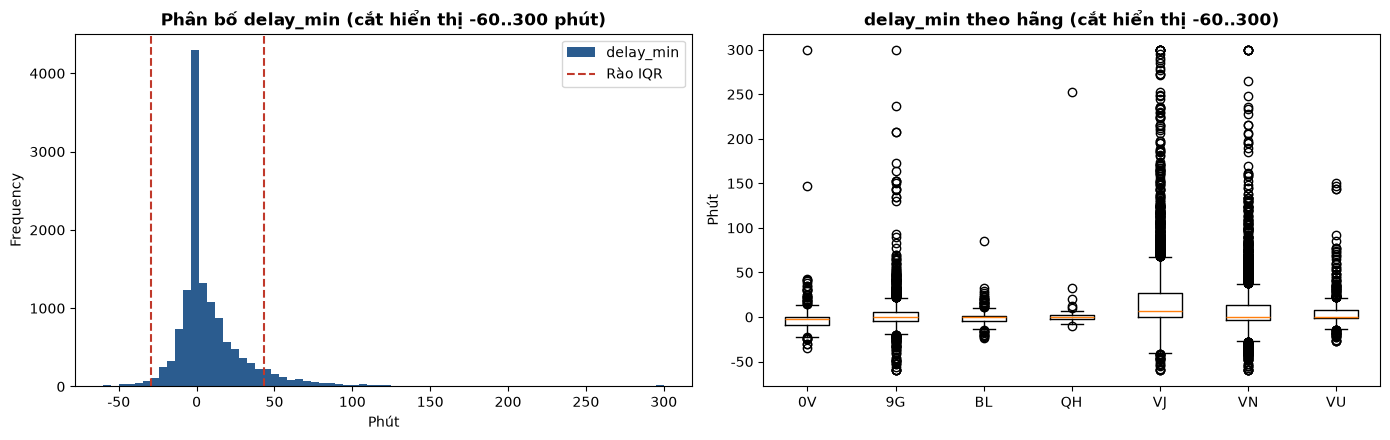

In [14]:
d = leg["delay_min"].dropna()
q = d.quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]).round(1)
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr = q3 - q1
low_b, high_b = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_iqr = int(((d < low_b) | (d > high_b)).sum())
n_early = int((d < processor.EARLY_LIMIT).sum())

# Số dòng lệch vòng ngày (trước khi hiệu chỉnh) (chỉ xét dòng có giờ thực tế/dự kiến dạng HH:MM)
def wrap_flag(r):
    s, _ = processor.parse_time_min(r["scheduled_time"])
    tgt = r["actual_time"] if str(r["actual_time"]).strip() else r["estimated_time"]
    t, off = processor.parse_time_min(tgt)
    if s is None or t is None or off != 0:
        return False
    return abs(t - s) > 720

n_wrap = int(side.apply(wrap_flag, axis=1).sum())

print(f"Số chuyến có delay_min tính được: {len(d):,} / {len(leg):,}")
display(q.to_frame("delay_min (phút)").T)
print(f"IQR: Q1 = {q1:.1f}, Q3 = {q3:.1f}, IQR = {iqr:.1f} -> ngưỡng [{low_b:.1f}, {high_b:.1f}] phút")
print(f"  Ngoài khoảng IQR (trễ/sớm thực tế, GIỮ NGUYÊN): {n_iqr:,} ({n_iqr / len(d) * 100:.2f}%)")
print(f"  delay_min < {processor.EARLY_LIMIT} (bay sớm bất thường -> unknown): {n_early:,}")
print(f"  Dòng có abs(T - S) > 720 phút (lệch vòng ngày, được hiệu chỉnh +/-1440 khi tính từ giờ): {n_wrap:,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
d.clip(-60, 300).plot(kind="hist", bins=70, ax=axes[0], color="#2b5c8f")
axes[0].axvline(low_b, color="#c0392b", ls="--", label="Rào IQR")
axes[0].axvline(high_b, color="#c0392b", ls="--")
axes[0].set_title("Phân bố delay_min (cắt hiển thị -60..300 phút)", fontweight="bold")
axes[0].set_xlabel("Phút")
axes[0].legend()
sub = leg[leg["delay_min"].notna()]
data_box = [g["delay_min"].clip(-60, 300).values for _, g in sub.groupby("airline_code")]
axes[1].boxplot(data_box, showfliers=True)
axes[1].set_xticklabels(list(sub.groupby("airline_code").groups))
axes[1].set_title("delay_min theo hãng (cắt hiển thị -60..300)", fontweight="bold")
axes[1].set_ylabel("Phút")
plt.tight_layout()
plt.show()

### 3.6. Tổng kết Bước 2
Sau tiền xử lý, dữ liệu đã:
- được **đưa về một schema chung** (12 cột) từ các nguồn có cấu trúc khác nhau;
- **khử trùng** từ snapshot → sự kiện cùng phía → chuyến bay duy nhất (đối chiếu chéo hàm băm và `processor`);
- có `origin`, `destination`, `route_type`, `leg_key`, `delay_min` đúng cả khi bay qua nửa đêm;
- có quyết định **loại cột** dựa trên tỷ lệ thiếu, và ngoại lai được **xử lý có chủ đích** thay vì xóa mù.

Bước 3 tiếp tục từ `leg` (một dòng/chuyến): chọn biến, gán nhãn, tạo đặc trưng và ghép thời tiết.

## 4. BƯỚC 3: BIẾN ĐỔI DỮ LIỆU (Data Transformation)

Mục tiêu của bước này là **chọn biến hữu ích và chuẩn bị dữ liệu cho phân tích**. Trình tự thực hiện:

| Mục | Việc làm | Hàm chính |
| :-: | :--- | :--- |
| 4.1 | Chọn biến và thiết kế schema đầu ra 24 cột | `CLEANED_FIELDS` |
| 4.2 | Gán nhãn đích `status_clean` (và `status`, `status_detail`) | `label_status`, `apply_labels` |
| 4.3 | Tạo đặc trưng thời gian và bối cảnh | `add_time_features`, `compute_airport_load` |
| 4.4 | Tích hợp thời tiết theo (sân bay, giờ bay) | `attach_weather` |
| 4.5 | Rời rạc hóa thành các *item* cho khai phá luật | `build_items` |
| 4.6 | Lắp ráp và kiểm định bộ dữ liệu cuối | `reindex(CLEANED_FIELDS)` |
| 4.7 | Khảo sát liên hệ giữa biến và nhãn (căn cứ chọn biến) | Cramér's V |

### 4.1. Lựa chọn biến và schema đầu ra
Schema đầu ra có **24 cột, một dòng = một chuyến bay**. Mỗi cột thuộc một nhóm và có một **vai trò** rõ ràng. Đặc biệt, các cột chứa **kết quả của chuyến bay** (`actual_time`, `delay_min`, `status`, `status_detail`) bị đánh dấu **rò rỉ nhãn (label leakage)**: chúng được dùng để *tạo nhãn* hoặc *kiểm tra*, **không** được dùng làm đặc trưng dự báo ở Bước 4.

In [15]:
# Mô tả từng cột của schema đầu ra: (nhóm, kiểu, vai trò, ý nghĩa / lý do giữ)
SCHEMA_DOC = {
    "leg_key":        ("Định danh", "text", "Định danh", "Khóa chuyến: flight_no|ngày|đi>đến. Dùng khử trùng, không làm đặc trưng."),
    "flight_date":    ("Định danh", "date", "Định danh", "Ngày bay theo lịch."),
    "flight_no":      ("Định danh", "text", "Định danh", "Số hiệu chuyến đã chuẩn hóa (vd. VJ123)."),
    "airline_code":   ("Định danh", "category", "Đặc trưng", "Hãng bay (VN, VJ, QH, BL, VU, 9G, 0V); khác biệt chất lượng đúng giờ giữa các hãng."),
    "origin":         ("Tuyến bay", "category", "Ngữ cảnh tuyến", "Sân bay đi (IATA). Nhiều giá trị, dùng khi cần phân tích theo tuyến."),
    "destination":    ("Tuyến bay", "category", "Ngữ cảnh tuyến", "Sân bay đến (IATA)."),
    "route_type":     ("Tuyến bay", "category", "Đặc trưng", "domestic / international, suy ra từ VN_AIRPORTS."),
    "airport":        ("Tuyến bay", "category", "Đặc trưng", "Sân bay quan sát bản ghi; là nơi lấy thời tiết và tải sân bay."),
    "direction":      ("Tuyến bay", "category", "Đặc trưng", "DEPARTURES / ARRIVALS tại sân bay quan sát."),
    "scheduled_time": ("Thời gian và bối cảnh", "time", "Ngữ cảnh", "Giờ bay theo lịch (HH:MM); cơ sở để suy ra time_slot và ghép thời tiết."),
    "actual_time":    ("Thời gian và bối cảnh", "time", "Rò rỉ nhãn", "Giờ thực tế; là kết quả của chuyến bay."),
    "delay_min":      ("Thời gian và bối cảnh", "float", "Rò rỉ nhãn", "Số phút trễ; cơ sở để tạo nhãn. Để trống với chuyến hủy."),
    "time_slot":      ("Thời gian và bối cảnh", "category", "Đặc trưng", "00h-06h / 06h-12h / 12h-18h / 18h-24h."),
    "day_type":       ("Thời gian và bối cảnh", "category", "Đặc trưng", "weekday / weekend."),
    "is_holiday":     ("Thời gian và bối cảnh", "bool", "Đặc trưng", "Ngày lễ Việt Nam (gói holidays)."),
    "airport_load":   ("Thời gian và bối cảnh", "int", "Đặc trưng", "Số chuyến (mọi hãng, cả đi và đến) cùng giờ tại sân bay; chỉ tính cho 5 sân bay được cào đầy đủ."),
    "precipitation":  ("Thời tiết", "float", "Đặc trưng", "Lượng mưa (mm/giờ) tại sân bay quan sát, đúng giờ bay dự kiến."),
    "wind_gusts_10m": ("Thời tiết", "float", "Đặc trưng", "Gió giật ở độ cao 10 m (km/h)."),
    "visibility":     ("Thời tiết", "float", "Đặc trưng", "Tầm nhìn (m); chỉ Forecast API có cột này."),
    "weather_code":   ("Thời tiết", "int", "Đặc trưng", "Mã thời tiết WMO (>= 95: dông)."),
    "status":         ("Nhãn", "text", "Rò rỉ nhãn", "Chuỗi trạng thái chuẩn, khớp với nhãn (Departed On-Time, Arrived N minutes late, Cancelled...)."),
    "status_detail":  ("Nhãn", "category", "Rò rỉ nhãn", "Trạng thái chi tiết (departed_late, arrived_on_time, on_time, delayed, cancelled...)."),
    "status_clean":   ("Nhãn", "category", "Nhãn đích", "NHÃN ĐÍCH: on_time / delayed / cancelled."),
    "source":         ("Nguồn", "category", "Truy vết nguồn", "Nguồn dữ liệu của bản ghi được giữ (chứng minh >= 2 nguồn)."),
}
rows = [{"Cột": c, "Nhóm": SCHEMA_DOC.get(c, ("?",) * 4)[0], "Kiểu": SCHEMA_DOC.get(c, ("?",) * 4)[1],
         "Vai trò": SCHEMA_DOC.get(c, ("?",) * 4)[2], "Ý nghĩa / lý do giữ": SCHEMA_DOC.get(c, ("?",) * 4)[3]}
        for c in CLEANED_FIELDS]
schema_df = pd.DataFrame(rows)
missing_doc = [c for c in CLEANED_FIELDS if c not in SCHEMA_DOC]
if missing_doc:
    print("(!) Cột chưa có mô tả trong SCHEMA_DOC (schema trong config.py đã thay đổi):", missing_doc)
print(f"=== BẢNG 4: SCHEMA ĐẦU RA ({len(CLEANED_FIELDS)} CỘT) ===")
display(schema_df)
display(schema_df["Vai trò"].value_counts().to_frame("Số cột"))

removed = pd.DataFrame([
    ("terminal, gate, extra", "Thiếu quá nhiều (63%-99% theo ghi chú trong config.py), vượt ngưỡng 40%."),
    ("other_airport, other_code", "Thay bằng origin, destination, route_type (rõ nghĩa hơn, không phụ thuộc phía quan sát)."),
    ("other_precipitation, dst_precipitation (DstRain)", "Thời tiết sân bay phía bên kia: thiếu nhiều (cùng tiêu chí > 40%) và dư thừa; mỗi chuyến chỉ giữ thời tiết tại `airport`."),
    ("estimated_time", "Chỉ dùng trung gian để tính delay_min và điền actual_time; không cần ở bộ dữ liệu cuối."),
    ("scraped_at, source_recorded_count, n_sides_seen", "Chỉ dùng khi khử trùng và truy vết; không phải đặc trưng."),
    ("cloud_cover", "Không còn được tải từ Open-Meteo (không nằm trong HOURLY của weather.py)."),
], columns=["Cột đã loại", "Lý do"])
print("=== BẢNG 5: CÁC CỘT ĐÃ LOẠI KHỎI SCHEMA VÀ LÝ DO ===")
display(removed)

=== BẢNG 4: SCHEMA ĐẦU RA (24 CỘT) ===


,Cột,Nhóm,Kiểu,Vai trò,Ý nghĩa / lý do giữ
0,leg_key,Định danh,text,Định danh,"Khóa chuyến: flight_no|ngày|đi>đến. Dùng khử trùng, không làm đặc trưng."
1,flight_date,Định danh,date,Định danh,Ngày bay theo lịch.
2,flight_no,Định danh,text,Định danh,Số hiệu chuyến đã chuẩn hóa (vd. VJ123).
3,airline_code,Định danh,category,Đặc trưng,"Hãng bay (VN, VJ, QH, BL, VU, 9G, 0V); khác biệt chất lượng đúng giờ giữa cá..."
4,origin,Tuyến bay,category,Ngữ cảnh tuyến,"Sân bay đi (IATA). Nhiều giá trị, dùng khi cần phân tích theo tuyến."
5,destination,Tuyến bay,category,Ngữ cảnh tuyến,Sân bay đến (IATA).
6,route_type,Tuyến bay,category,Đặc trưng,"domestic / international, suy ra từ VN_AIRPORTS."
7,airport,Tuyến bay,category,Đặc trưng,Sân bay quan sát bản ghi; là nơi lấy thời tiết và tải sân bay.
8,direction,Tuyến bay,category,Đặc trưng,DEPARTURES / ARRIVALS tại sân bay quan sát.
9,scheduled_time,Thời gian và bối cảnh,time,Ngữ cảnh,Giờ bay theo lịch (HH:MM); cơ sở để suy ra time_slot và ghép thời tiết.


,Số cột
Vai trò,
Đặc trưng,12
Rò rỉ nhãn,4
Định danh,3
Ngữ cảnh tuyến,2
Ngữ cảnh,1
Nhãn đích,1
Truy vết nguồn,1


=== BẢNG 5: CÁC CỘT ĐÃ LOẠI KHỎI SCHEMA VÀ LÝ DO ===


,Cột đã loại,Lý do
0,"terminal, gate, extra","Thiếu quá nhiều (63%-99% theo ghi chú trong config.py), vượt ngưỡng 40%."
1,"other_airport, other_code","Thay bằng origin, destination, route_type (rõ nghĩa hơn, không phụ thuộc phí..."
2,"other_precipitation, dst_precipitation (DstRain)",Thời tiết sân bay phía bên kia: thiếu nhiều (cùng tiêu chí > 40%) và dư thừa...
3,estimated_time,Chỉ dùng trung gian để tính delay_min và điền actual_time; không cần ở bộ dữ...
4,"scraped_at, source_recorded_count, n_sides_seen",Chỉ dùng khi khử trùng và truy vết; không phải đặc trưng.
5,cloud_cover,Không còn được tải từ Open-Meteo (không nằm trong HOURLY của weather.py).


### 4.2. Gán nhãn đích `status_clean`
`label_status()` trả về bộ ba **(`status`, `status_detail`, `status_clean`)** cho mỗi dòng. Chuỗi `status` luôn **khớp với nhãn**: trước đây một chuyến trễ 5 phút vẫn hiển thị "Departed 5 minutes late" nhưng được gán on-time; nay chuỗi và nhãn nhất quán, số phút chính xác nằm ở `delay_min`.

| `status_clean` | `status_detail` | `status` chuẩn |
| :--- | :--- | :--- |
| `on_time` | `departed_on_time`, `arrived_on_time`, `on_time` | "Departed On-Time", "Arrived On-Time", "On-Time" |
| `delayed` | `departed_late`, `arrived_late`, `delayed` | "Departed N minutes late", "Arrived N minutes late", "Delayed N minutes" |
| `cancelled` | `cancelled` | "Cancelled" |
| *(loại khỏi khai phá)* | `scheduled`, `diverted`, `unknown` | — |

Ngưỡng quyết định: `delay_min ≥ THRESHOLD` (mặc định 15 phút) → `delayed`; ngược lại `on_time`. `delay_min` của chuyến hủy được đặt trống.

Dưới đây gán nhãn cho `leg` ở **hai ngưỡng 15 và 30 phút** để thấy độ nhạy của nhãn theo ngưỡng.

=== BẢNG 6: PHÂN BỐ NHÃN THEO NGƯỠNG TRỄ (trên tập chuyến bay duy nhất) ===


,Ngưỡng 15 phút,Ngưỡng 30 phút
status_clean,,
on_time,9904,11482
delayed,3571,1993
cancelled,95,95
unknown,40,40
TỔNG,13610,13610


Mẫu hợp lệ cho khai phá (ngưỡng 15'): 13,570 / 13,610 chuyến (99.7%)

Lý do bị loại khỏi khai phá (status_detail của các dòng không hợp lệ):


,Số chuyến
status_detail,
scheduled,28
diverted,11
unknown,1


Phân bố status_detail của mẫu hợp lệ:


status_clean,cancelled,delayed,on_time
status_detail,,,
arrived_late,0,1230,0
arrived_on_time,0,0,2834
cancelled,95,0,0
delayed,0,7,0
departed_late,0,2334,0
departed_on_time,0,0,5714
on_time,0,0,1356


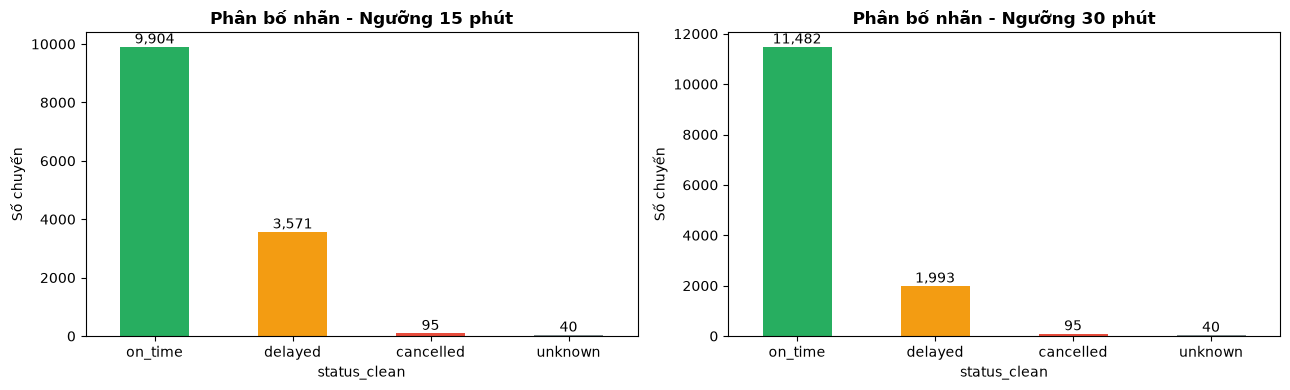

In [16]:
leg15 = processor.apply_labels(leg, 15)
leg30 = processor.apply_labels(leg, 30)
LABELS = processor.LABELS

cmp_lab = pd.DataFrame({"Ngưỡng 15 phút": leg15["status_clean"].value_counts(),
                        "Ngưỡng 30 phút": leg30["status_clean"].value_counts()}).fillna(0).astype(int)
cmp_lab.loc["TỔNG"] = cmp_lab.sum()
print("=== BẢNG 6: PHÂN BỐ NHÃN THEO NGƯỠNG TRỄ (trên tập chuyến bay duy nhất) ===")
display(cmp_lab)

valid_mask = leg15["status_clean"].isin(LABELS)
print(f"Mẫu hợp lệ cho khai phá (ngưỡng {THRESHOLD}'): {int(valid_mask.sum()):,} / {len(leg15):,} chuyến "
      f"({valid_mask.mean() * 100:.1f}%)")
print("\nLý do bị loại khỏi khai phá (status_detail của các dòng không hợp lệ):")
display(leg15.loc[~valid_mask, "status_detail"].value_counts().to_frame("Số chuyến"))

print("Phân bố status_detail của mẫu hợp lệ:")
display(pd.crosstab(leg15.loc[valid_mask, "status_detail"], leg15.loc[valid_mask, "status_clean"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = {"on_time": "#27ae60", "delayed": "#f39c12", "cancelled": "#e74c3c"}
for ax, col in zip(axes, ["Ngưỡng 15 phút", "Ngưỡng 30 phút"]):
    s = cmp_lab[col].drop("TỔNG")
    s.plot(kind="bar", ax=ax, color=[colors.get(i, "#7f8c8d") for i in s.index])
    ax.set_title(f"Phân bố nhãn - {col}", fontweight="bold")
    ax.set_ylabel("Số chuyến")
    ax.tick_params(axis="x", rotation=0)
    for i, v in enumerate(s.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

### 4.3. Đặc trưng thời gian và bối cảnh
Các đặc trưng được suy ra từ giờ bay **theo lịch** (không dùng thông tin sau chuyến bay nên không rò rỉ nhãn):

- `time_slot`: chia ngày thành 4 khung `00h-06h`, `06h-12h`, `12h-18h`, `18h-24h`.
- `day_type`: `weekday` / `weekend` (thứ Bảy, Chủ nhật).
- `is_holiday`: ngày lễ Việt Nam, dùng gói `holidays`. **Nếu chưa cài gói này, cột bị đặt `False` toàn bộ** (processor có in cảnh báo).
- `airport_load`: số chuyến **của mọi hãng, cả đi và đến**, có giờ dự kiến trong cùng giờ tại sân bay quan sát. Chỉ tính cho 5 sân bay được cào đầy đủ; sân bay khác để trống thay vì đưa con số sai. Khi rời rạc hóa, tải được chia thành `low/mid/high` theo **tertile của chính sân bay đó** (để so sánh công bằng giữa sân bay lớn và nhỏ).

Gói 'holidays': ĐÃ CÀI


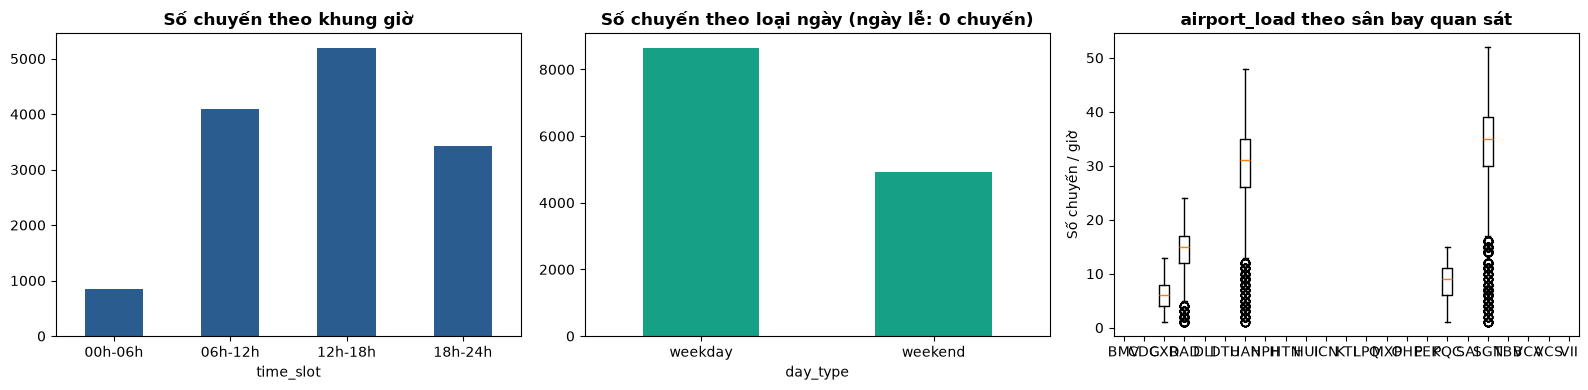

,count,mean,std,min,25%,50%,75%,max
airport_load,13521.0,25.993196,12.410184,1.0,15.0,30.0,36.0,52.0


airport_load bị trống (sân bay không nằm trong 5 sân bay được theo dõi): 49 chuyến (0.4%)


In [17]:
print("Gói 'holidays':", "ĐÃ CÀI" if importlib.util.find_spec("holidays") else "CHƯA CÀI -> is_holiday đang là False cho mọi dòng")
v = leg15[leg15["status_clean"].isin(LABELS)].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = ["00h-06h", "06h-12h", "12h-18h", "18h-24h"]
v["time_slot"].value_counts().reindex(order).plot(kind="bar", ax=axes[0], color="#2b5c8f")
axes[0].set_title("Số chuyến theo khung giờ", fontweight="bold")
axes[0].tick_params(axis="x", rotation=0)
v["day_type"].value_counts().plot(kind="bar", ax=axes[1], color="#16a085")
axes[1].set_title(f"Số chuyến theo loại ngày (ngày lễ: {int(v['is_holiday'].sum()):,} chuyến)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=0)
loads = [g["airport_load"].dropna().values for _, g in v.groupby("airport")]
axes[2].boxplot(loads)
axes[2].set_xticklabels(list(v.groupby("airport").groups))
axes[2].set_title("airport_load theo sân bay quan sát", fontweight="bold")
axes[2].set_ylabel("Số chuyến / giờ")
plt.tight_layout()
plt.show()

display(v[["airport_load"]].describe().T)
print("airport_load bị trống (sân bay không nằm trong 5 sân bay được theo dõi):",
      f"{v['airport_load'].isna().sum():,} chuyến ({v['airport_load'].isna().mean() * 100:.1f}%)")

### 4.4. Tích hợp thời tiết theo (sân bay quan sát, giờ bay dự kiến)
Dữ liệu thời tiết theo giờ (`weather.load_weather()`: JSON gốc `open_meteo/` gộp với cache `weather_hourly.csv`, ưu tiên giá trị không rỗng của lần tải mới nhất) được **nối trái** vào từng chuyến theo khóa `(airport, hour_floor)`, trong đó `hour_floor` là giờ bay theo lịch làm tròn xuống.

- **Chọn sân bay để lấy thời tiết:** mỗi chuyến chỉ có thời tiết của sân bay được theo dõi. Khi một chuyến được thấy ở cả hai phía mà thông tin tương đương, **phía ở sân bay được theo dõi** được ưu tiên (chuyến quốc tế từ nước ngoài về dùng thời tiết của sân bay Việt Nam).
- **`visibility`:** Archive API **không có** biến này, chỉ Forecast API có, nên 90 ngày gần nhất dùng Forecast.
- Thiếu thời tiết (chưa chạy `main.py weather`, hoặc chuyến ngoài khoảng ngày đã tải) được để trống, **không điền giả**.

######## processor.attach_weather ########
def attach_weather(df):
    """Gộp thời tiết (từ JSON gốc open_meteo + cache CSV) vào từng chuyến theo (sân bay quan sát, giờ bay dự kiến)."""
    derived = ["rain_level", "wind_level", "vis_level"]
    wx = load_weather()
    if wx.empty:
        print("(!) Chưa có dữ liệu thời tiết -> các cột thời tiết để trống. Chạy: python main.py weather")
        for c in WX_COLS + derived:
            df[c] = np.nan
        return df

    base = wx[["airport", "time"] + WX_COLS].rename(columns={"time": "hour_floor"})
    df = df.merge(base, on=["airport", "hour_floor"], how="left")
    df["rain_level"] = _cut(df["precipitation"], [0, 0.1, 2.5, 1e9], ["none", "light", "heavy"])
    df["wind_level"] = _cut(df["wind_gusts_10m"], [0, 30, 50, 1e9], ["<30", "30-50", ">50"])
    df["vis_level"] = _cut(df["visibility"], [0, 5000, 1e9], ["<5km", ">=5km"])
    return df

Bảng thời tiết theo giờ: 3,120 dòng


,So_gio,Tu,Den,thiếu_%_precipitation,thiếu_%_wind_gusts_10m,thiếu_%_visibility,thiếu_%_weather_code
airport,,,,,,,
CXR,624,2026-10-08,2026-11-02 23:00:00,0.0,0.0,0.0,0.0
DAD,624,2026-10-08,2026-11-02 23:00:00,0.0,0.0,0.0,0.0
HAN,624,2026-10-08,2026-11-02 23:00:00,0.0,0.0,0.0,0.0
PQC,624,2026-10-08,2026-11-02 23:00:00,0.0,0.0,0.0,0.0
SGN,624,2026-10-08,2026-11-02 23:00:00,0.0,0.0,0.0,0.0



Tỷ lệ chuyến CÓ dữ liệu thời tiết sau khi ghép (%), theo sân bay quan sát:


,precipitation,wind_gusts_10m,visibility,weather_code
airport,,,,
BMV,0.0,0.0,0.0,0.0
CDG,0.0,0.0,0.0,0.0
CXR,99.2,99.2,99.2,99.2
DAD,100.0,100.0,100.0,100.0
DLI,0.0,0.0,0.0,0.0
DTU,0.0,0.0,0.0,0.0
HAN,100.0,100.0,100.0,100.0
HPH,0.0,0.0,0.0,0.0
HTN,0.0,0.0,0.0,0.0


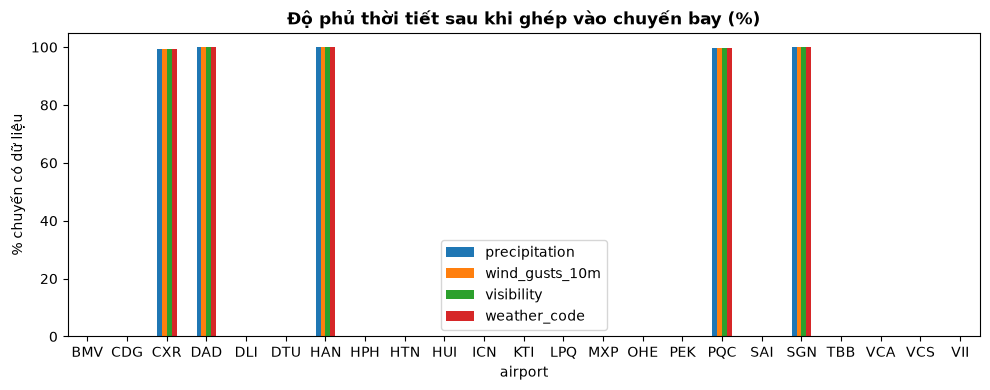

In [18]:
print("######## processor.attach_weather ########")
show_src(processor.attach_weather, 30)

wx = weather.load_weather()
if wx.empty:
    print("(!) Chưa có dữ liệu thời tiết. Chạy: python main.py weather")
else:
    wx_sum = wx.groupby("airport").agg(So_gio=("time", "count"), Tu=("time", "min"), Den=("time", "max"))
    miss_wx = wx.groupby("airport")[weather.WX_COLS].apply(lambda g: g.isna().mean() * 100).round(1)
    print(f"Bảng thời tiết theo giờ: {len(wx):,} dòng")
    display(wx_sum.join(miss_wx.add_prefix("thiếu_%_")))

wcols = ["precipitation", "wind_gusts_10m", "visibility", "weather_code"]
cov = v.groupby("airport")[wcols].apply(lambda g: g.notna().mean() * 100).round(1)
cov.loc["TẤT CẢ"] = (v[wcols].notna().mean() * 100).round(1)
print("\nTỷ lệ chuyến CÓ dữ liệu thời tiết sau khi ghép (%), theo sân bay quan sát:")
display(cov)

fig, ax = plt.subplots(figsize=(10, 4))
cov.drop("TẤT CẢ").plot(kind="bar", ax=ax)
ax.set_ylim(0, 105)
ax.set_title("Độ phủ thời tiết sau khi ghép vào chuyến bay (%)", fontweight="bold")
ax.set_ylabel("% chuyến có dữ liệu")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

### 4.5. Rời rạc hóa thành các *item* phục vụ khai phá luật kết hợp
Luật kết hợp (FP-Growth) làm việc với **tập item rời rạc**, nên các biến liên tục được chia mức. Mỗi chuyến trở thành một *giao dịch* gồm các item dạng `Tên=Giá trị`.

| Biến gốc | Item | Cách chia |
| :--- | :--- | :--- |
| `airline_code`, `airport`, `direction`, `route_type`, `time_slot`, `day_type` | `Airline=`, `Airport=`, `Dir=`, `Route=`, `Slot=`, `Day=` | Giữ nguyên giá trị phân loại |
| `is_holiday` | `Holiday=yes` | Chỉ tạo item khi là ngày lễ |
| `airport_load` | `Load=low/mid/high` | Tertile **theo từng sân bay** |
| `precipitation` | `Rain=none/light/heavy` | `[0, 0.1)`, `[0.1, 2.5)`, `≥ 2.5` mm/giờ |
| `wind_gusts_10m` | `Gust=<30 / 30-50 / >50` | km/h |
| `visibility` | `Vis=<5km / >=5km` | Ngưỡng 5000 m |
| `weather_code` | `Storm=yes` | Mã WMO ≥ 95 (dông) |
| `status_clean` | `Status=on_time/delayed/cancelled` | Nhãn đích (vế phải của luật) |

Giá trị thiếu **không tạo item** (thiếu thời tiết không bị coi là "không mưa").

Phân bố các mức rời rạc hóa (NaN = thiếu dữ liệu, không tạo item):


,Rain (precipitation),Gust (wind_gusts_10m),Vis (visibility),Load (airport_load)
30-50,0,940,0,0
<30,0,12581,0,0
<5km,0,0,1502,0
>=5km,0,0,12019,0
heavy,259,0,0,0
high,0,0,0,4742
light,5033,0,0,0
low,0,0,0,4766
mid,0,0,0,4013
none,8229,0,0,0


Dòng có weather_code >= 95 (Storm=yes): 189

Ma trận item: 13,570 giao dịch x 54 item (kiểu boolean, sẵn sàng cho FP-Growth)


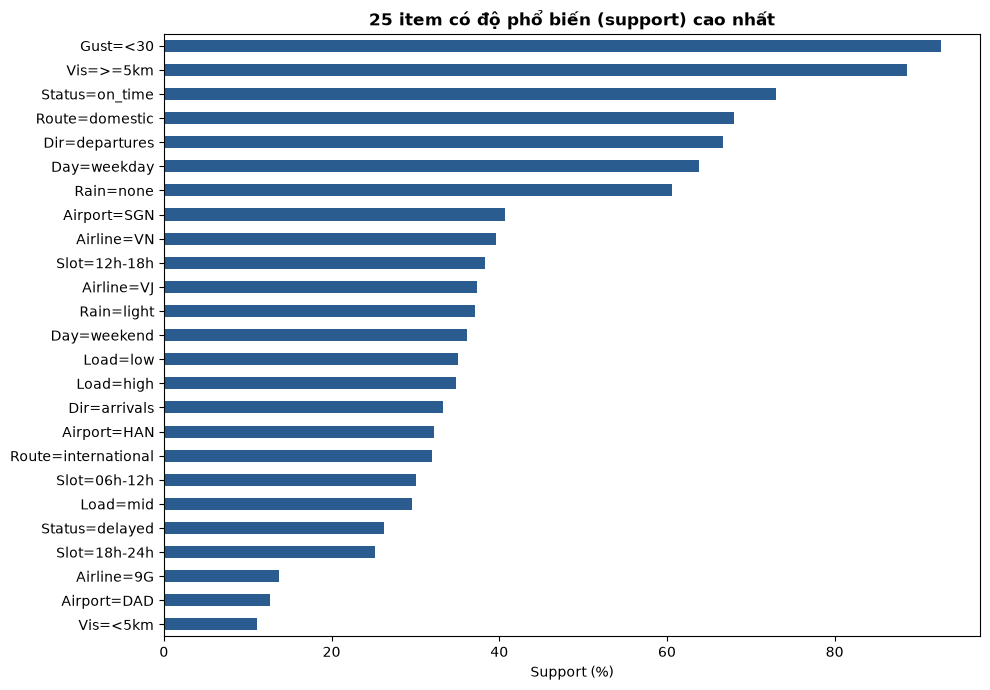

In [19]:
v["load_level"] = processor._load_level(v)
disc = pd.DataFrame({
    "Rain (precipitation)":   v["rain_level"].value_counts(dropna=False),
    "Gust (wind_gusts_10m)":  v["wind_level"].value_counts(dropna=False),
    "Vis (visibility)":       v["vis_level"].value_counts(dropna=False),
    "Load (airport_load)":    v["load_level"].value_counts(dropna=False),
})
print("Phân bố các mức rời rạc hóa (NaN = thiếu dữ liệu, không tạo item):")
display(disc.fillna(0).astype(int))
print(f"Dòng có weather_code >= 95 (Storm=yes): {int((v['weather_code'] >= 95).sum()):,}")

items = processor.build_items(v)
print(f"\nMa trận item: {items.shape[0]:,} giao dịch x {items.shape[1]} item (kiểu boolean, sẵn sàng cho FP-Growth)")
top_items = items.mean().sort_values(ascending=False).head(25).mul(100).round(1)
fig, ax = plt.subplots(figsize=(10, 7))
top_items[::-1].plot(kind="barh", ax=ax, color="#2b5c8f")
ax.set_title("25 item có độ phổ biến (support) cao nhất", fontweight="bold")
ax.set_xlabel("Support (%)")
plt.tight_layout()
plt.show()

### 4.6. Lắp ráp và kiểm định bộ dữ liệu cuối
Bộ dữ liệu cuối là `valid.reindex(columns=CLEANED_FIELDS)`: các cột trung gian (`sched_dt`, `hour_floor`, `other_code`, `rain_level`, ...) bị bỏ, đúng 24 cột theo đúng thứ tự schema. Các kiểm định dưới đây khẳng định các ràng buộc của bộ dữ liệu.

> Bật `SAVE_OUTPUT = True` ở ô khai báo đầu notebook nếu muốn ghi bộ dữ liệu này ra `data/flights_cleaned_global.csv`. Cách thông thường vẫn là `python main.py process`.

In [20]:
final = v.reindex(columns=CLEANED_FIELDS).replace("", np.nan)
print(f"Bộ dữ liệu cuối: {final.shape[0]:,} dòng x {final.shape[1]} cột (ngưỡng trễ = {THRESHOLD} phút)\n")

checks = [
    ("Đúng 24 cột theo đúng thứ tự CLEANED_FIELDS", list(final.columns) == CLEANED_FIELDS),
    ("leg_key duy nhất (1 dòng = 1 chuyến)", bool(final["leg_key"].is_unique)),
    ("status_clean chỉ gồm on_time / delayed / cancelled", set(final["status_clean"].dropna()) <= set(LABELS)),
    ("Không còn status_clean trống", bool(final["status_clean"].notna().all())),
    ("delay_min trống với mọi chuyến hủy", bool(final.loc[final["status_clean"] == "cancelled", "delay_min"].isna().all())),
    (f"delay_min >= {processor.EARLY_LIMIT} phút ở mọi dòng có giá trị", bool((final["delay_min"].dropna() >= processor.EARLY_LIMIT).all())),
    ("Nhãn khớp với chuỗi status (chuyến hủy <-> 'Cancelled')",
     bool(((final["status_clean"] == "cancelled") == (final["status"] == "Cancelled")).all())),
    ("Có ít nhất 2 nguồn dữ liệu", final["source"].nunique() >= 2),
]
display(pd.DataFrame([{"Kiểm định": n, "Kết quả": "ĐẠT" if ok else "KHÔNG ĐẠT"} for n, ok in checks]))
print("route_type có giá trị:", f"{final['route_type'].notna().mean() * 100:.1f}% (phần thiếu là chuyến chưa suy ra được sân bay đối ứng)")

print("\nKiểu dữ liệu và 5 dòng đầu:")
display(final.dtypes.astype(str).to_frame("dtype").T)
display(final.head(5))

print("\nTỷ lệ thiếu theo cột (cột > 40% được cảnh báo để cân nhắc bỏ):")
processor.print_missing_report(final)

if FILE_CLEANED.exists():
    old = pd.read_csv(FILE_CLEANED, nrows=3)
    n_old = sum(1 for _ in open(FILE_CLEANED, encoding="utf-8-sig")) - 1
    print(f"\nTệp {FILE_CLEANED.name} hiện có: {n_old:,} dòng, {old.shape[1]} cột "
          f"(cùng schema: {list(old.columns) == CLEANED_FIELDS}). Chạy 'python main.py process' để cập nhật nếu dữ liệu đã thay đổi.")
if SAVE_OUTPUT:
    final.to_csv(FILE_CLEANED, index=False, encoding="utf-8-sig")
    print(f"\n=> Đã ghi {FILE_CLEANED}")

Bộ dữ liệu cuối: 13,570 dòng x 24 cột (ngưỡng trễ = 15 phút)



,Kiểm định,Kết quả
0,Đúng 24 cột theo đúng thứ tự CLEANED_FIELDS,ĐẠT
1,leg_key duy nhất (1 dòng = 1 chuyến),ĐẠT
2,status_clean chỉ gồm on_time / delayed / cancelled,ĐẠT
3,Không còn status_clean trống,ĐẠT
4,delay_min trống với mọi chuyến hủy,ĐẠT
5,delay_min >= -90 phút ở mọi dòng có giá trị,ĐẠT
6,Nhãn khớp với chuỗi status (chuyến hủy <-> 'Cancelled'),ĐẠT
7,Có ít nhất 2 nguồn dữ liệu,ĐẠT


route_type có giá trị: 100.0% (phần thiếu là chuyến chưa suy ra được sân bay đối ứng)

Kiểu dữ liệu và 5 dòng đầu:


,leg_key,flight_date,flight_no,airline_code,origin,destination,route_type,airport,direction,scheduled_time,actual_time,delay_min,time_slot,day_type,is_holiday,airport_load,precipitation,wind_gusts_10m,visibility,weather_code,status,status_detail,status_clean,source
dtype,str,str,str,str,str,str,str,str,str,str,str,float64,object,str,bool,float64,float64,float64,float64,float64,str,str,str,str


,leg_key,flight_date,flight_no,airline_code,origin,destination,route_type,airport,direction,scheduled_time,actual_time,delay_min,time_slot,day_type,is_holiday,airport_load,precipitation,wind_gusts_10m,visibility,weather_code,status,status_detail,status_clean,source
0,0V8024|2026-10-28|SGN>DLI,2026-10-28,0V8024,0V,SGN,DLI,domestic,SGN,DEPARTURES,18:20,18:17,-3.0,18h-24h,weekday,False,41.0,0.0,16.2,26400.0,3.0,Departed On-Time,departed_on_time,on_time,guide_sgn
1,0V8024|2026-10-29|SGN>DLI,2026-10-29,0V8024,0V,SGN,DLI,domestic,SGN,DEPARTURES,18:20,18:20,0.0,18h-24h,weekday,False,41.0,0.1,11.5,12580.0,51.0,Departed On-Time,departed_on_time,on_time,guide_sgn
2,0V8024|2026-10-30|SGN>DLI,2026-10-30,0V8024,0V,SGN,DLI,domestic,SGN,DEPARTURES,18:20,18:14,-6.0,18h-24h,weekday,False,42.0,0.0,12.6,22620.0,3.0,Departed On-Time,departed_on_time,on_time,guide_sgn
3,0V8024|2026-10-31|SGN>DLI,2026-10-31,0V8024,0V,SGN,DLI,domestic,SGN,DEPARTURES,18:20,NaN,0.0,18h-24h,weekend,False,47.0,0.0,7.9,18280.0,2.0,On-Time,on_time,on_time,guide_sgn
4,0V8024|2026-11-01|SGN>DLI,2026-11-01,0V8024,0V,SGN,DLI,domestic,SGN,DEPARTURES,18:20,18:20,0.0,18h-24h,weekend,False,43.0,0.0,8.3,29640.0,1.0,Departed On-Time,departed_on_time,on_time,guide_sgn



Tỷ lệ thiếu theo cột (cột > 40% được cảnh báo để cân nhắc bỏ):
--------------------------------------------------------------
TỶ LỆ THIẾU THEO CỘT (bộ dữ liệu cuối)
  actual_time             10.7%
  delay_min                0.8%
  airport_load             0.4%
  wind_gusts_10m           0.4%
  precipitation            0.4%
  visibility               0.4%
  weather_code             0.4%
  day_type                 0.1%
  time_slot                0.1%

Tệp flights_cleaned_global.csv hiện có: 13,570 dòng, 24 cột (cùng schema: True). Chạy 'python main.py process' để cập nhật nếu dữ liệu đã thay đổi.


### 4.7. Khảo sát liên hệ giữa biến và nhãn (căn cứ chọn biến)
Trước khi khai phá, ta đo **mức độ liên hệ** giữa từng biến phân loại và nhãn `status_clean` bằng **hệ số Cramér's V** (0 = độc lập, 1 = phụ thuộc hoàn toàn):

$$\chi^2 = \sum \frac{(O - E)^2}{E}, \qquad V = \sqrt{\frac{\chi^2}{n \cdot (\min(r, c) - 1)}}$$

Với $O$ là tần số quan sát, $E$ là tần số kỳ vọng khi hai biến độc lập, $r, c$ là số dòng/cột của bảng chéo. Các biến **rò rỉ nhãn** (`delay_min`, `status`, `status_detail`, `actual_time`) bị loại khỏi phép đo này.

> **Lưu ý diễn giải:** V chỉ đo mức **liên hệ**, không chứng minh **quan hệ nhân quả** (mưa lớn *đi kèm* trễ chưa có nghĩa mưa *gây* trễ). Một biến có V thấp vẫn có thể xuất hiện trong luật kết hợp hữu ích với lớp hiếm như `cancelled`.

=== BẢNG 7: MỨC LIÊN HỆ GIỮA BIẾN PHÂN LOẠI VÀ NHÃN status_clean ===


,Biến,Số dòng dùng,Số giá trị,Cramér's V
0,airline_code,13570,7,0.1733
1,airport,13570,23,0.1608
4,time_slot,13559,4,0.1216
5,day_type,13559,2,0.0568
7,load_level,13521,3,0.0414
8,rain_level,13521,3,0.0325
3,route_type,13570,2,0.0316
9,wind_level,13521,2,0.0276
2,direction,13570,2,0.0249
10,vis_level,13521,2,0.0236


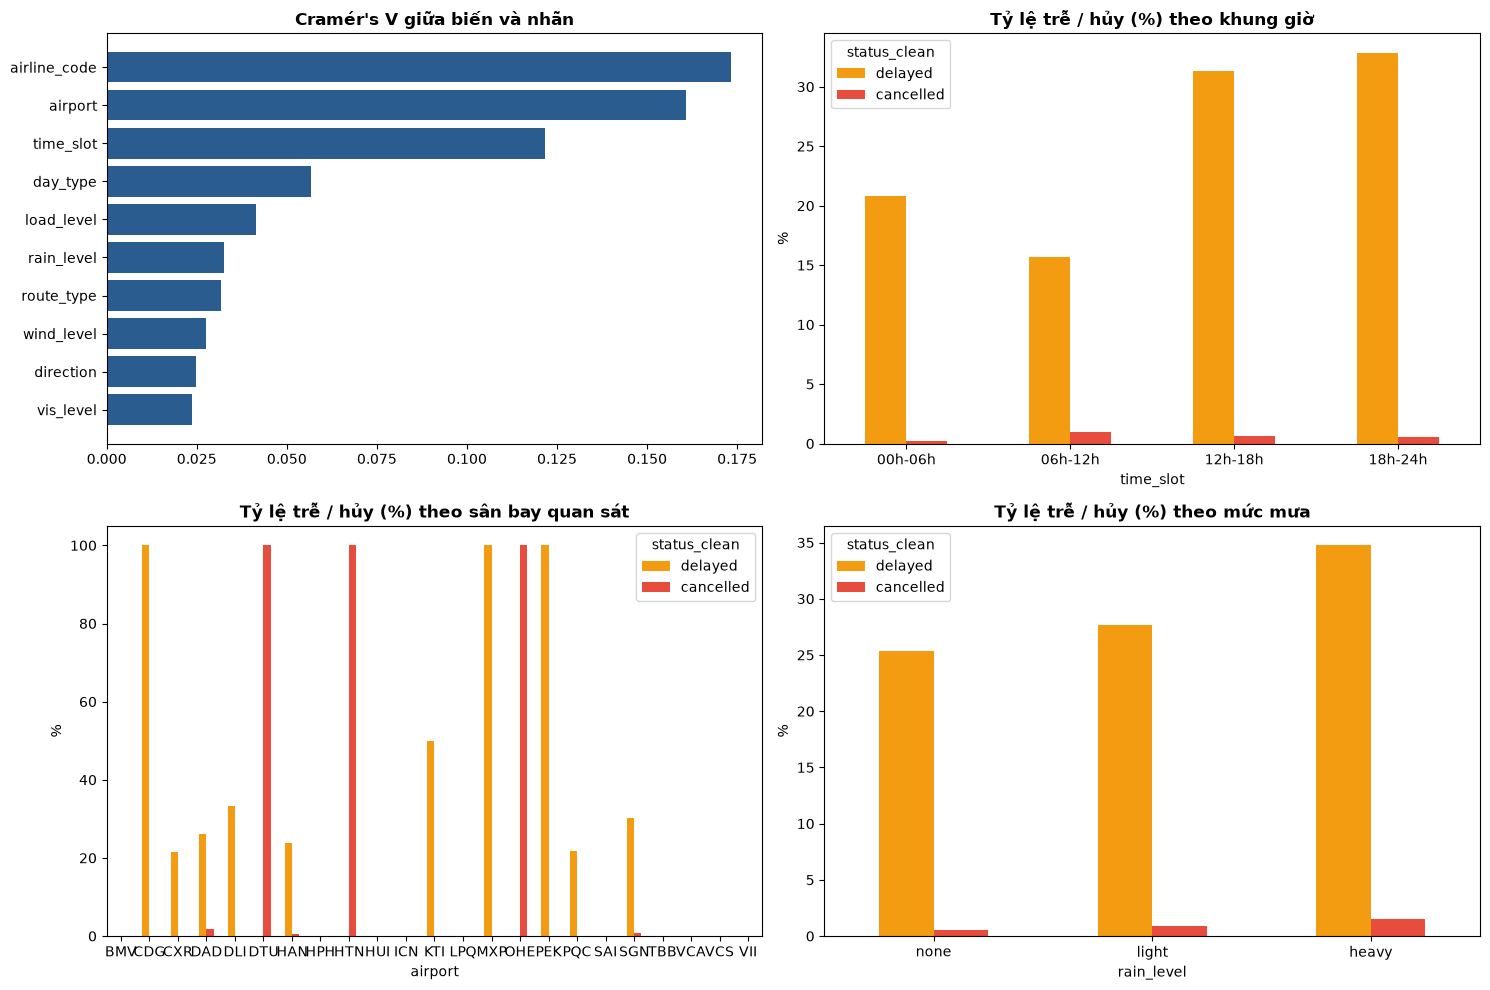

In [21]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    obs = ct.values.astype(float)
    n = obs.sum()
    exp = obs.sum(axis=1, keepdims=True) @ obs.sum(axis=0, keepdims=True) / n
    chi2 = ((obs - exp) ** 2 / exp).sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))

cat_feats = ["airline_code", "airport", "direction", "route_type", "time_slot", "day_type",
             "is_holiday", "load_level", "rain_level", "wind_level", "vis_level"]
vv = v.copy()
vv["is_holiday"] = vv["is_holiday"].astype(str)
vres = []
for c in cat_feats:
    m = vv[c].notna() & (vv[c].astype(str) != "")
    vres.append({"Biến": c, "Số dòng dùng": int(m.sum()), "Số giá trị": vv.loc[m, c].nunique(),
                 "Cramér's V": round(cramers_v(vv.loc[m, c], vv.loc[m, "status_clean"]), 4) if m.sum() > 1 else np.nan})
vres = pd.DataFrame(vres).sort_values("Cramér's V", ascending=False)
print("=== BẢNG 7: MỨC LIÊN HỆ GIỮA BIẾN PHÂN LOẠI VÀ NHÃN status_clean ===")
display(vres)

def rate_by(col, order=None):
    t = pd.crosstab(vv[col], vv["status_clean"], normalize="index").mul(100)
    for k in ["delayed", "cancelled"]:
        if k not in t.columns:
            t[k] = 0.0
    t = t[["delayed", "cancelled"]]
    return t.reindex(order) if order else t

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
vr = vres.dropna().sort_values("Cramér's V")
axes[0, 0].barh(vr["Biến"], vr["Cramér's V"], color="#2b5c8f")
axes[0, 0].set_title("Cramér's V giữa biến và nhãn", fontweight="bold")
rate_by("time_slot", ["00h-06h", "06h-12h", "12h-18h", "18h-24h"]).plot(kind="bar", ax=axes[0, 1], color=["#f39c12", "#e74c3c"])
axes[0, 1].set_title("Tỷ lệ trễ / hủy (%) theo khung giờ", fontweight="bold")
rate_by("airport").plot(kind="bar", ax=axes[1, 0], color=["#f39c12", "#e74c3c"])
axes[1, 0].set_title("Tỷ lệ trễ / hủy (%) theo sân bay quan sát", fontweight="bold")
rate_by("rain_level", ["none", "light", "heavy"]).plot(kind="bar", ax=axes[1, 1], color=["#f39c12", "#e74c3c"])
axes[1, 1].set_title("Tỷ lệ trễ / hủy (%) theo mức mưa", fontweight="bold")
for ax in axes.flat[1:]:
    ax.tick_params(axis="x", rotation=0)
    ax.set_ylabel("%")
plt.tight_layout()
plt.show()

#### Lệch mẫu (sampling bias) khi đối chiếu với số liệu chính thức
Lệnh `api --status cancelled,landed` **chủ động lấy nhiều chuyến hủy** để bù lớp hiếm. Do đó tỷ lệ hủy/trễ trong mẫu **không thể so trực tiếp** với số liệu chính thức (`OFFICIAL_STATS`). Luật kết hợp và độ nâng (*lift*) vẫn có giá trị **trong phạm vi mẫu**, nhưng cần nêu rõ hạn chế này trong báo cáo. Bảng dưới cho thấy mức độ lệch theo từng nguồn.

In [22]:
print("Phân bố nhãn theo nguồn của bản ghi được giữ (% theo dòng):")
display(pd.crosstab(v["source"], v["status_clean"], normalize="index").mul(100).round(1)
        .join(v["source"].value_counts().rename("Số chuyến")))

print("\nTỷ lệ theo hãng, đặt cạnh số liệu chính thức (chỉ để tham khảo, KHÔNG so trực tiếp vì lệch mẫu):")
display(processor.airline_table(v))

Phân bố nhãn theo nguồn của bản ghi được giữ (% theo dòng):


,cancelled,delayed,on_time,Số chuyến
source,,,,
aviationstack_api,8.8,46.0,45.3,914
guide_cxr,0.0,19.6,80.4,694
guide_dad,0.5,25.0,74.5,1609
guide_han,0.1,22.0,77.9,4028
guide_pqc,0.0,20.3,79.7,1162
guide_sgn,0.1,28.8,71.1,5163



Tỷ lệ theo hãng, đặt cạnh số liệu chính thức (chỉ để tham khảo, KHÔNG so trực tiếp vì lệch mẫu):


,Hãng,Số chuyến,Trễ (%),Hủy (%),OTP (%),Chính thức: trễ,Chính thức: hủy,Chính thức: OTP
7,ALL,13570,26.3,0.70,73.0,22.3,0.6,
5,VN,5375,23.3,1.47,75.3,,,78.0
4,VJ,5055,38.3,0.24,61.5,,,75.2
1,9G,1863,13.2,0.00,86.8,,,
6,VU,532,16.7,0.38,82.9,,,
0,0V,445,6.5,0.00,93.5,,,
2,BL,268,6.7,0.75,92.5,,,
3,QH,32,9.4,0.00,90.6,,,


### 4.8. Tổng kết Bước 3 và các bước tiếp theo

**Đã hoàn thành đến hết Bước 3:**
- Thu thập từ 3 loại nguồn (website, REST API, API thời tiết) và **lưu bản gốc** (HTML, JSON) với chuỗi truy vết `source_file`.
- Dựng lớp CSV thô từ JSON gốc, mỗi nguồn giữ cột riêng; tích hợp về schema chuẩn 12 cột.
- Khử trùng ba cấp (đối chiếu chéo bằng SHA-256), xử lý giá trị thiếu theo ngưỡng 40% và ngoại lai có chủ đích.
- Gán nhãn đích nhất quán (`status`, `status_detail`, `status_clean`), tạo đặc trưng thời gian/bối cảnh, ghép thời tiết theo giờ và rời rạc hóa.
- Bộ dữ liệu cuối **24 cột, 1 dòng = 1 chuyến**, qua các kiểm định ràng buộc.

**Hạn chế cần nêu trong báo cáo:**
1. Mẫu lệch về chuyến hủy do bộ lọc API (mục 4.7); dữ liệu thu trong thời gian ngắn nên chưa thấy được chu kỳ tuần/mùa.
2. Dữ liệu thu trước khi lưu HTML/JSON chỉ còn CSV đã parse; không khôi phục được bản gốc.
3. Thời tiết là giá trị theo giờ tại tọa độ sân bay, chỉ xấp xỉ điều kiện thực tế trên đường băng.
4. `airport_load` chỉ tính trên 5 sân bay được cào đầy đủ.

**Bước tiếp theo:**
- *Bước 4 – Khai phá:* FP-Growth cho `Status=delayed` và `Status=cancelled` (`python main.py process --compare 30`); có thể bổ sung mô hình phân loại (không dùng các cột rò rỉ nhãn ở mục 4.1) và chia tập theo thời gian.
- *Bước 5 – Đánh giá:* kiểm tra luật trên các ngày chưa dùng, báo cáo support/confidence/lift và hạn chế.
- *Bước 6 – Ứng dụng:* bảng rủi ro trễ/hủy theo điều kiện hoặc hàm chấm điểm rủi ro.